In [2]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from scipy.interpolate import griddata
import mplstereonet
import cmasher as cmr


from stratmodel import (
    StratModel, Fault, Unconformity, build_treemesh,
    sample_density_points,
)
from strat_raytrace import trace_rays_density
from strat_plot import plot_layer_stack_slice

from healpix_detector import make_healpix_detector

In [ ]:
# Functions for applying the Equation 2.4 and 2.5 perspective corrections to an opacity map
# An interactive version (TiltExplorer) on an opacity plot is included at the end

def pov_correction(elevs, data):
    # Vertical component of the input data
    return data * np.sin(np.radians(elevs))

def tilted_axis(offset_deg, toward_azimuth_deg):
    """Unit axis tilted `offset_deg` away from vertical, towards compass azimuth `toward_azimuth_deg`.

        n = (sin(offset) sin(az), sin(offset) cos(az), cos(offset))      # (east, north, up)

    offset_deg = 0 is vertical
    """
    d, a = np.radians(offset_deg), np.radians(toward_azimuth_deg)
    return np.array([np.sin(d) * np.sin(a), np.sin(d) * np.cos(a), np.cos(d)])

def project_opacity(opacity, dirs, axis=(0.0, 0.0, 1.0)):
    """opacity * (ray direction . axis), for any number of rays.

    opacity : (...,)    opacity along each ray
    dirs    : (..., 3)  ray directions in the same frame as `axis` (normalised here), e.g.
                        healpix_detector's `det.central_dirs`
    axis    : (3,)      projection axis, e.g. tilted_axis(offset_deg, toward_azimuth_deg)
                        (normalised here). Default = vertical, i.e. opacity * sin(elevation).

    Returns an array shaped like `opacity`. The result is signed so it goes negative for rays
    that point behind a tilted axis.
    """
    dirs = np.asarray(dirs, dtype=float)
    dirs = dirs / np.linalg.norm(dirs, axis=-1, keepdims=True)
    axis = np.asarray(axis, dtype=float)
    axis = axis / np.linalg.norm(axis)
    return np.asarray(opacity, dtype=float) * (dirs @ axis)

def project_opacity_angles(opacity, az_deg, el_deg, offset_deg, toward_azimuth_deg):
    """The same projection with angles:

        O * [ sin(el) cos(offset) + cos(el) sin(offset) cos(az - toward_azimuth) ]
    """
    el, az = np.radians(el_deg), np.radians(az_deg)
    off, tow = np.radians(offset_deg), np.radians(toward_azimuth_deg)
    return np.asarray(opacity, dtype=float) * (
        np.sin(el) * np.cos(off) + np.cos(el) * np.sin(off) * np.cos(az - tow))

In [4]:
# Cross-section plotting functions
def get_polar_section(
    dpred,
    dirs_vec,
    line_x=None,
    line_y=None,
    sample_res=100,
):
    if line_x is None:
        line_x = np.linspace(
            np.min(dirs_vec[:,0]),
            np.max(dirs_vec[:,0]),
            sample_res)
        
    if line_y is None:
        line_y = np.linspace(
            np.average(dirs_vec[:,1]),
            np.average(dirs_vec[:,1]),
            sample_res)

    sampled_values = griddata(
        (dirs_vec[:,0].flatten(),
         dirs_vec[:,1].flatten()),
        dpred,
        (line_x, line_y),
        method='cubic')
    
    line_position = (
        np.sqrt(line_x**2 + line_y**2)
        * np.sign(line_x)
    )
    return line_position, sampled_values

def plot_polar_section(
    dpred,
    dirs_vec,
    line_x=None,
    line_y=None,
    x_lim=[None,None],
    y_lim=[None,None],
    plt_scatter=True,
    plt_line=True,
    ax=None,
    show=False,
    figsize=(14,6),
    lw=5,
    with_grid=True,
    grid_style='dotted',
    **kwargs
):

    line_position, sampled_values = get_polar_section(
        dpred, dirs_vec, line_x, line_y, **kwargs)

    if ax is None:
        fig, ax = plt.subplots(figsize=figsize)

    xdata = np.degrees(line_position)

    if plt_scatter:
        ax.scatter(xdata, sampled_values, s=30, c='darkred', marker='s', zorder=1)
    if plt_line:
        ax.plot(xdata, sampled_values, linewidth=lw, c='black', zorder=0)
    ax.ticklabel_format(style='plain', axis='y', useOffset=False)
    ax.yaxis.set_major_formatter('{x:.0f}')
    if x_lim:
        ax.set_xlim(x_lim[0], x_lim[1])
    if y_lim:
        ax.set_ylim(y_lim[0], y_lim[1])

    # #ax.set_title("Opacity plot section")
    # ax.set_xlabel("Degrees from vertical", labelpad=10, fontsize=20)
    # ax.set_ylabel("Opacity ($kg\ m^{-2}$)", labelpad=10, fontsize=20)
    ax.grid(with_grid, linestyle=grid_style, color='0.5')

    ax.set_axisbelow(True)
    #ax.set_aspect('auto')

    if show:
        plt.show()

    return ax, line_position, sampled_values

def layer_thickness_at(model, layer_name, x, y):
    layer = model.layers[layer_name]
    top_interp = model.horizon_interpolator(layer.top)
    base_interp = model.horizon_interpolator(layer.base)
    z_top = top_interp([[y, x]])[0]   # note: (y, x) order
    z_base = base_interp([[y, x]])[0]
    return z_top - z_base

In [5]:
# Detector object that can be reused by shifting the origin
det = make_healpix_detector(origin=(1500,1500,0),
                            angular_resolution_deg=3,
                            min_elevation_deg=45)

<Axes: >

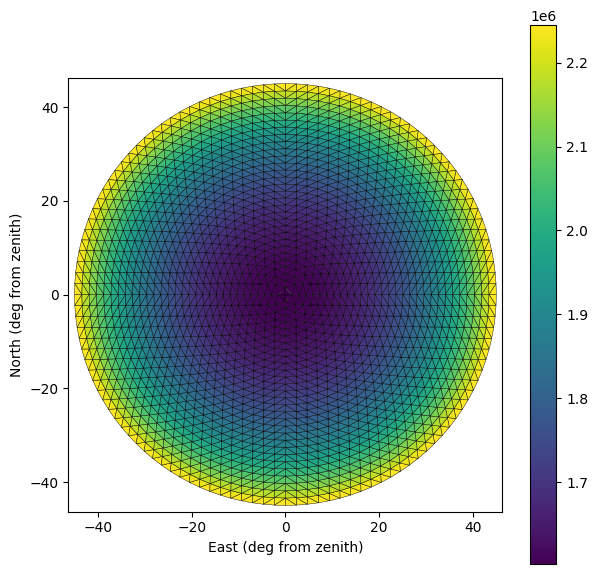

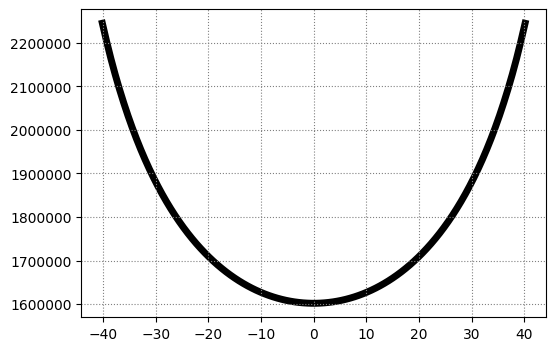

In [6]:
# Background for an empty model at 600m depth, background 2670 kg m^-3
det.origin = [1500, 1500, 0]

#Defining the stratmodel
regional_dip = 0
regional_strike = 0

model = StratModel(nx=300, ny=300, dx=10)
model.add_basement(noise_scale=None, dip=regional_dip, strike=regional_strike)
model.deposit('h1', mean=600, noise_scale=None, rel_dip=0, rel_strike=regional_strike)
model.set_density("basement__h1", mean=2670, std=0)

#Calling the forward operactor
result = trace_rays_density(model, det.origin, det.central_dirs)
opacity = np.array([r.density_integral for r in result])
#Plotting result
det.plot_sky(values=opacity)
plot_polar_section(opacity, det.central_dirs, figsize=(6,4), plt_scatter=False)[0]

<span style="font-size:30px; font-weight:bold;">Dipping slab</span>

<Axes: >

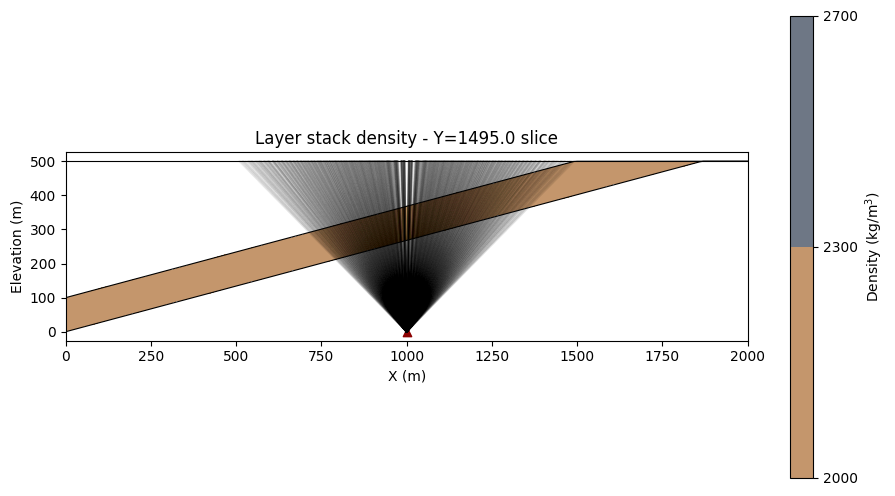

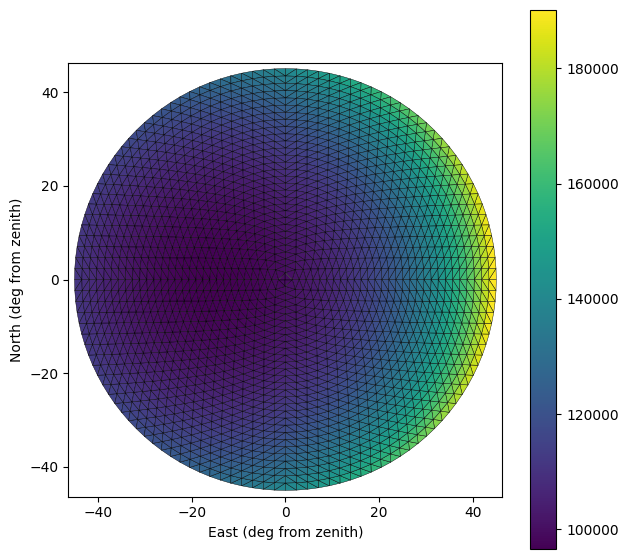

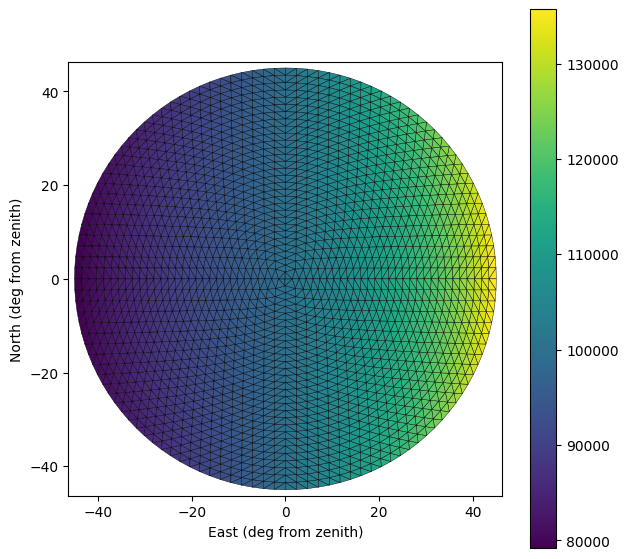

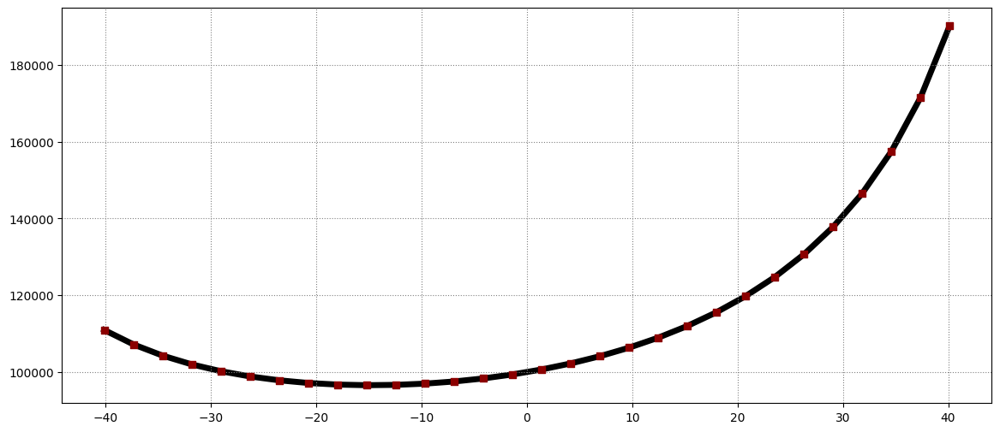

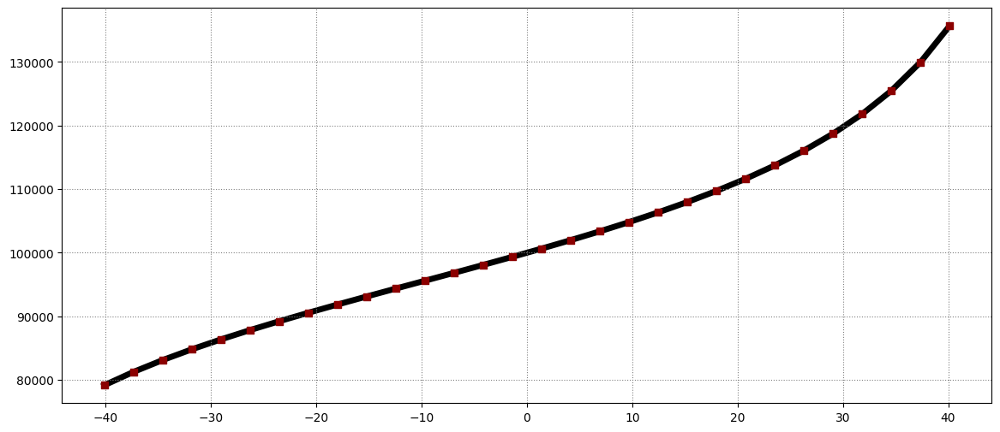

In [ ]:
det.origin = [1000, 1500, 0]

# Adjust 'regional dip/strike' to alter the dip of the slab
regional_dip = 15
regional_strike = 90

model = StratModel(nx=300, ny=300, dx=10)
model.add_basement(noise_scale=None, dip=regional_dip, strike=regional_strike)
model.deposit('h1', mean=100, noise_scale=None, rel_dip=0, rel_strike=regional_strike)

topo = Unconformity(dip=0, strike=90, z0=500)
model.apply_unconformity(topo)

#model.order, model.layer_order
model.set_density("basement__h1", mean=1000, std=0)


result = trace_rays_density(model, det.origin, det.central_dirs)
opacity = np.array([r.density_integral for r in result])
dstop = np.array([r.t_stop for r in result])

boundaries = [2000, 2300,2700]   # kg/m^3 bin edges
colors     = ["#c4966c", "#6e7785"]

cmap = ListedColormap(colors)
norm = BoundaryNorm(boundaries, cmap.N)

fig, ax = plot_layer_stack_slice(model, cmap=cmap, norm=norm)[:2]
ax.scatter(det.origin[0], det.origin[2], marker='^', c='darkred')
for i, d in zip(det.central_dirs, dstop):
    ax.plot((det.origin[0], i[0]*d+det.origin[0]), (det.origin[2], i[2]*d+det.origin[2]),
            c='black', alpha=0.02)
ax.set_xlim(0,2000)
ax.set_aspect('equal')

det.plot_sky(values=opacity)
# Taking vertical component
det.plot_sky(values=pov_correction(det.elevation_deg, opacity))

plot_polar_section(opacity, det.central_dirs, sample_res=30)[0]
plot_polar_section(pov_correction(det.elevation_deg, opacity), det.central_dirs, sample_res=30)[0]

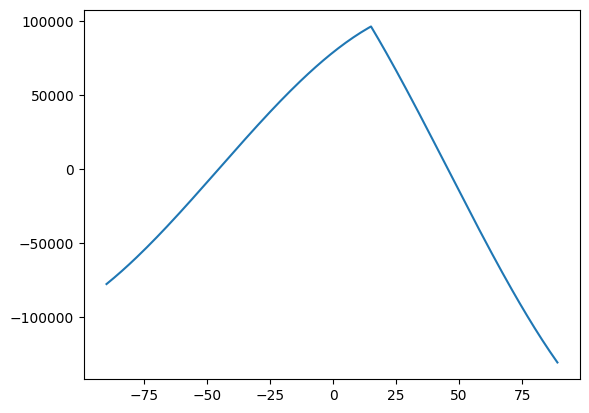

In [ ]:
# When applying Equation 2.5 to a unit of consistent stratigraphic thickness,
# the minimum opacity value is maximised when phi applied = unit dip
fig = plt.figure()
ax = fig.add_subplot()
x_vals = np.arange(-90, 90,1)
y_vals = []
for i in x_vals:
    y_vals.append(project_opacity_angles((opacity), det.azimuth_deg, det.elevation_deg, i, 270).min())
ax.plot(x_vals, y_vals)

<Axes: >

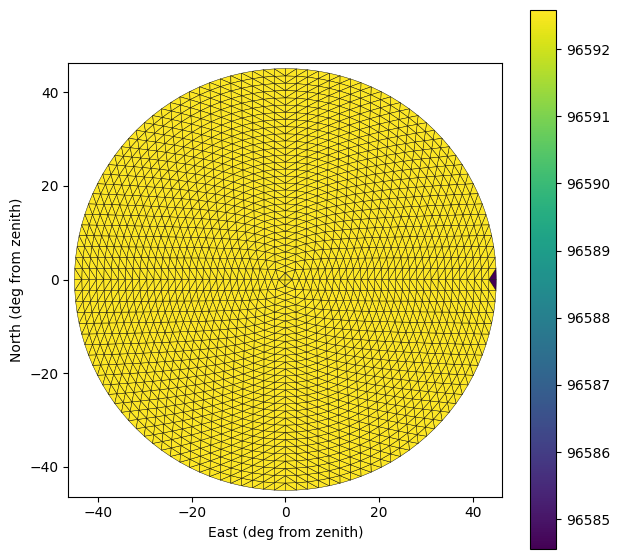

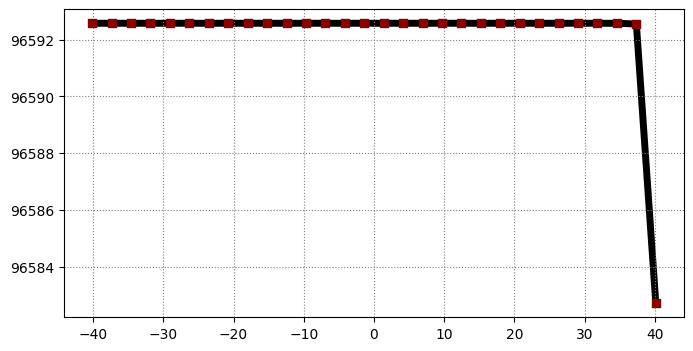

In [ ]:
#Try other 'angle' values (phi in Equation 2.5)
angle=15
direction=270
det.plot_sky(values=project_opacity_angles(opacity, det.azimuth_deg, det.elevation_deg, angle, direction))
plot_polar_section(project_opacity_angles(opacity, det.azimuth_deg, det.elevation_deg, angle, direction), det.central_dirs, figsize=(8,4), sample_res=30)[0]

<span style="font-size:30px; font-weight:bold;">Stacked stratigraphy / faulted wedge</span>

<Axes: >

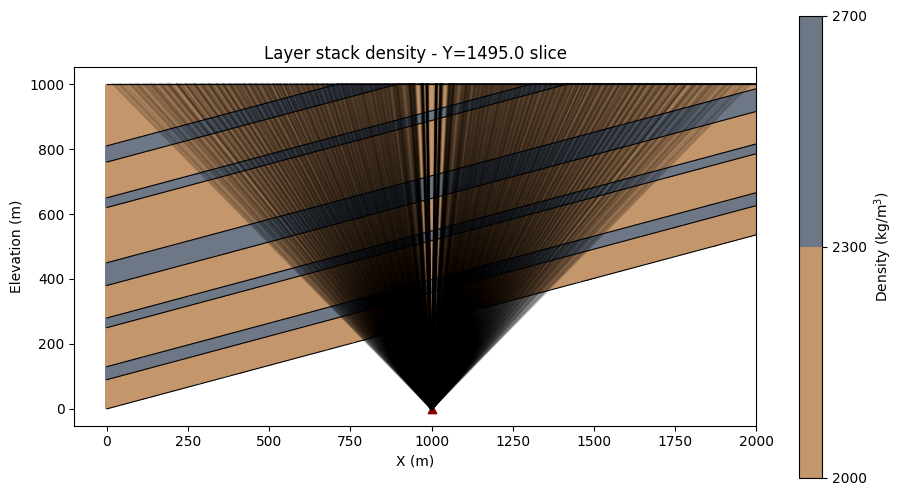

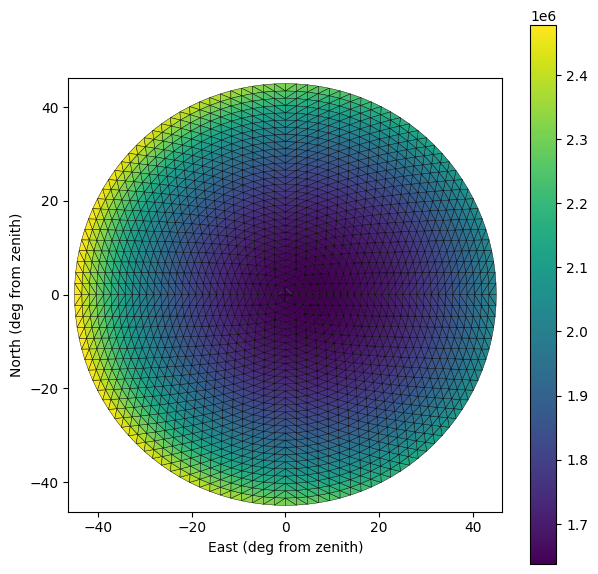

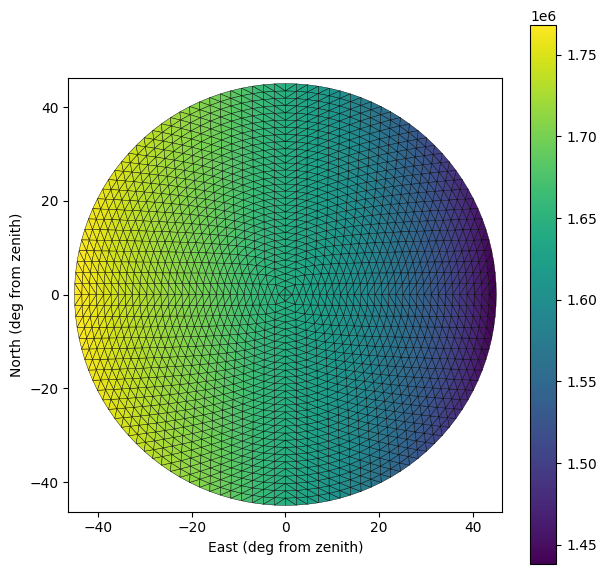

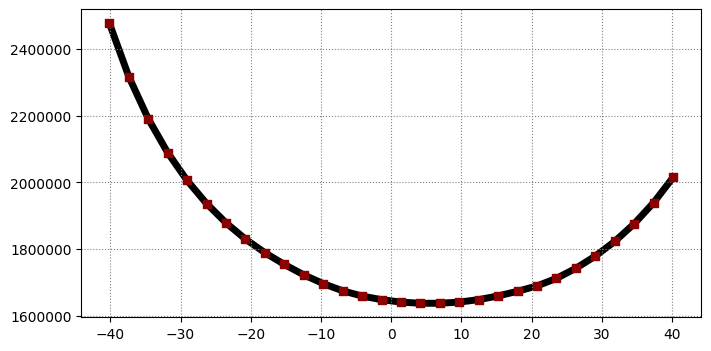

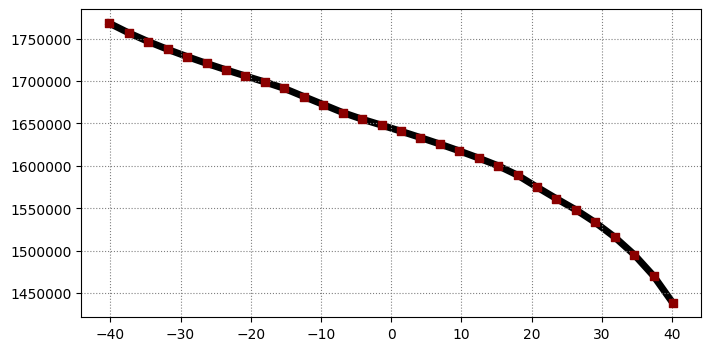

In [93]:
det.origin = [1000, 1500, 0]

regional_dip = 15
regional_strike = 90

model = StratModel(nx=300, ny=300, dx=10)

model.add_basement(noise_scale=None, dip=regional_dip, strike=regional_strike)
model.deposit('h1', mean=90, noise_scale=None, rel_dip=0, rel_strike=regional_strike)
model.deposit('h2', mean=40, noise_scale=None, rel_dip=0, rel_strike=regional_strike)
model.deposit('h3', mean=120, noise_scale=None, rel_dip=0, rel_strike=regional_strike)
model.deposit('h4', mean=30, noise_scale=None, rel_dip=0, rel_strike=regional_strike)
model.deposit('h5', mean=100, noise_scale=None, rel_dip=0, rel_strike=regional_strike)
model.deposit('h6', mean=70, noise_scale=None, rel_dip=0, rel_strike=regional_strike)
model.deposit('h7', mean=170, noise_scale=None, rel_dip=0, rel_strike=regional_strike)
model.deposit('h8', mean=30, noise_scale=None, rel_dip=0, rel_strike=regional_strike)
model.deposit('h9', mean=110, noise_scale=None, rel_dip=0, rel_strike=regional_strike)
model.deposit('h10', mean=50, noise_scale=None, rel_dip=0, rel_strike=regional_strike)
model.deposit('h11', mean=200, noise_scale=None, rel_dip=0, rel_strike=regional_strike)

topo = Unconformity(dip=0, strike=90, z0=1000)
model.apply_unconformity(topo)

#model.order, model.layer_order

ind=0
for lname in model.layer_order:
    if ind % 2 == 0:
        model.set_density(lname, mean=2200, std=0)
    else:
        model.set_density(lname, mean=2400, std=0)
    layer = model.layers[lname]
    ind += 1

result = trace_rays_density(model, det.origin, det.central_dirs)
opacity = np.array([r.density_integral for r in result])
dstop = np.array([r.t_stop for r in result])

boundaries = [2000, 2300,2700]   # kg/m^3 bin edges
colors     = ["#c4966c", "#6e7785"]  # one fewer color than boundaries

cmap = ListedColormap(colors)
norm = BoundaryNorm(boundaries, cmap.N)

fig, ax = plot_layer_stack_slice(model, cmap=cmap, norm=norm)[:2]
ax.scatter(det.origin[0], det.origin[2], marker='^', c='darkred')
for i, d in zip(det.central_dirs, dstop):
    ax.plot((det.origin[0], i[0]*d+det.origin[0]), (det.origin[2], i[2]*d+det.origin[2]),
            c='black', alpha=0.05)
ax.set_xlim((-100, 2000))
ax.set_aspect('equal')

det.plot_sky(values=opacity)
det.plot_sky(values=pov_correction(det.elevation_deg, opacity))

plot_polar_section(opacity, det.central_dirs, figsize=(8,4), sample_res=30)[0]
plot_polar_section(pov_correction(det.elevation_deg, opacity), det.central_dirs, figsize=(8,4), sample_res=30)[0]

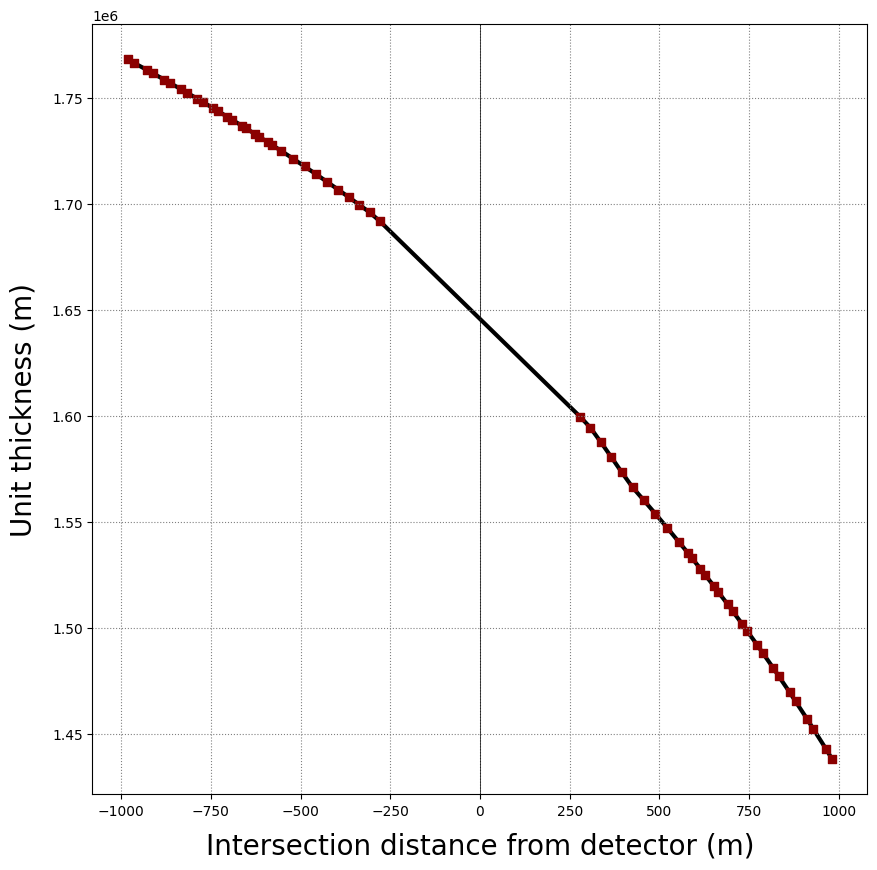

In [98]:
horizontal_distance = np.array([
    r.t_stop * np.cos(np.radians(el)) if r.t_stop is not None else np.nan
    for r, el in zip(result, det.elevation_deg)
])

#plot_data = opacity
#plot_data = np.tan(det.elevation_deg)
plot_data = pov_correction(det.elevation_deg, opacity)

target_az = 88
opposite_az = (target_az + 180) % 360
tol = 1

mask_pos = np.isclose(det.azimuth_deg, target_az, atol=tol)
mask_neg = np.isclose(det.azimuth_deg, opposite_az, atol=tol)

h_dist_signed = np.concatenate([-horizontal_distance[mask_neg], horizontal_distance[mask_pos]])
opacity_slice = np.concatenate([plot_data[mask_neg], plot_data[mask_pos]])

order = np.argsort(h_dist_signed)
h_dist_signed = h_dist_signed[order]
opacity_slice = opacity_slice[order]

plt.figure(figsize=(10,10))
plt.scatter(h_dist_signed, opacity_slice, marker='s', c='darkred', s=40, zorder=1)
plt.plot(h_dist_signed, opacity_slice, c='black', linewidth=3, zorder=0)
plt.axvline(0, color='k', lw=0.5)
plt.xlabel('Intersection distance from detector (m)', fontsize=20, labelpad=10)
plt.ylabel('Unit thickness (m)', fontsize=20, labelpad=10)
plt.grid(True, linestyle='dotted', color='0.5')
#plt.gca().set_aspect(15)

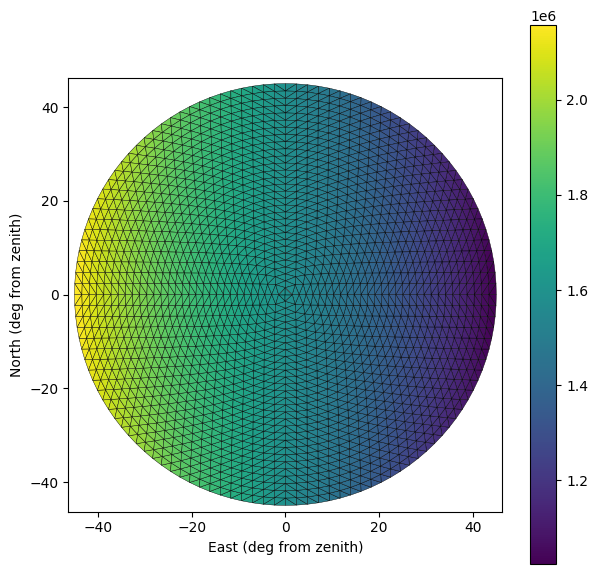

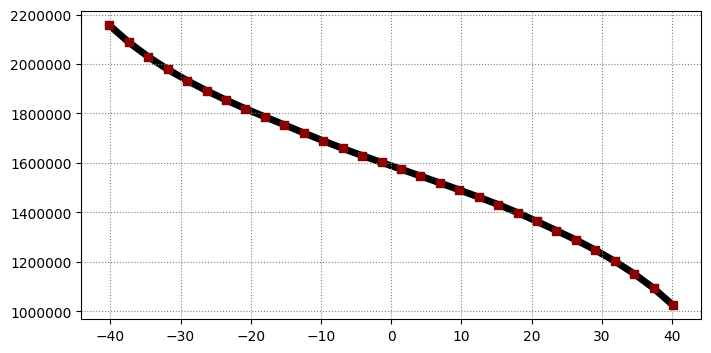

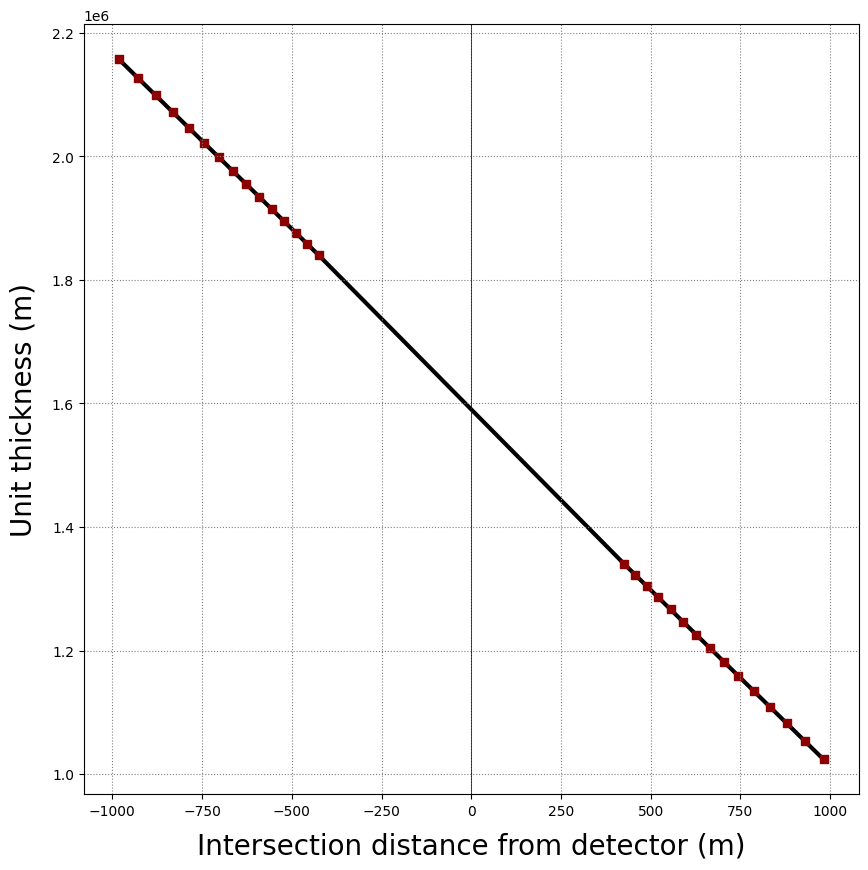

In [44]:
angle=15
direc=270
det.plot_sky(values=project_opacity_angles(opacity, det.azimuth_deg, det.elevation_deg, angle, direc))
plot_polar_section(project_opacity_angles(opacity, det.azimuth_deg, det.elevation_deg, angle, direc), det.central_dirs, figsize=(8,4), sample_res=30)[0]

horizontal_distance = np.array([
    r.t_stop * np.cos(np.radians(el)) if r.t_stop is not None else np.nan
    for r, el in zip(result, det.elevation_deg)
])

plot_data = project_opacity_angles(opacity, det.azimuth_deg, det.elevation_deg, angle, direc)

target_az = 89
opposite_az = (target_az + 180) % 360
tol = 1

mask_pos = np.isclose(det.azimuth_deg, target_az, atol=tol)
mask_neg = np.isclose(det.azimuth_deg, opposite_az, atol=tol)

h_dist_signed = np.concatenate([-horizontal_distance[mask_neg], horizontal_distance[mask_pos]])
opacity_slice = np.concatenate([plot_data[mask_neg], plot_data[mask_pos]])

order = np.argsort(h_dist_signed)
h_dist_signed = h_dist_signed[order]
opacity_slice = opacity_slice[order]

plt.figure(figsize=(10,10))
plt.scatter(h_dist_signed, opacity_slice, marker='s', c='darkred', s=40, zorder=1)
plt.plot(h_dist_signed, opacity_slice, c='black', linewidth=3, zorder=0)
plt.axvline(0, color='k', lw=0.5)
plt.xlabel('Intersection distance from detector (m)', fontsize=20, labelpad=10)
plt.ylabel('Unit thickness (m)', fontsize=20, labelpad=10)
plt.grid(True, linestyle='dotted', color='0.5')
#plt.gca().set_aspect(15)

<span style="font-size:30px; font-weight:bold;">Thickness-density mapping</span>

basement__h1: uniform, mean density set above


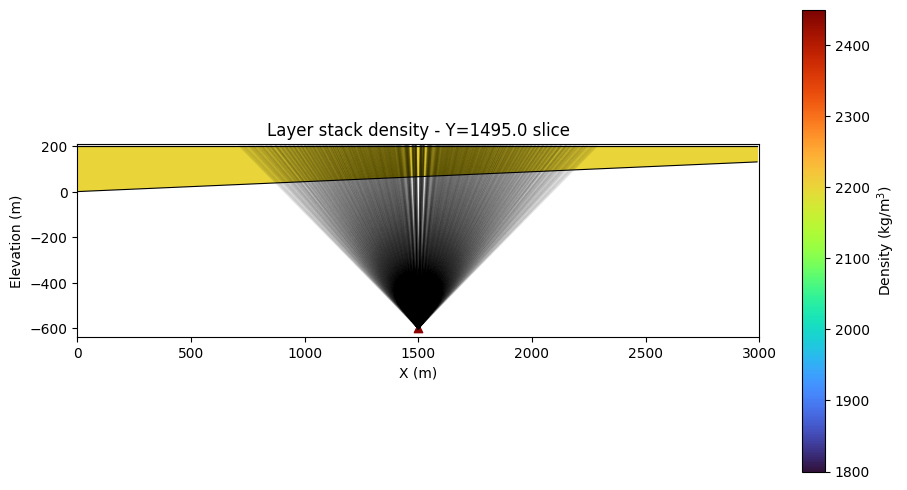

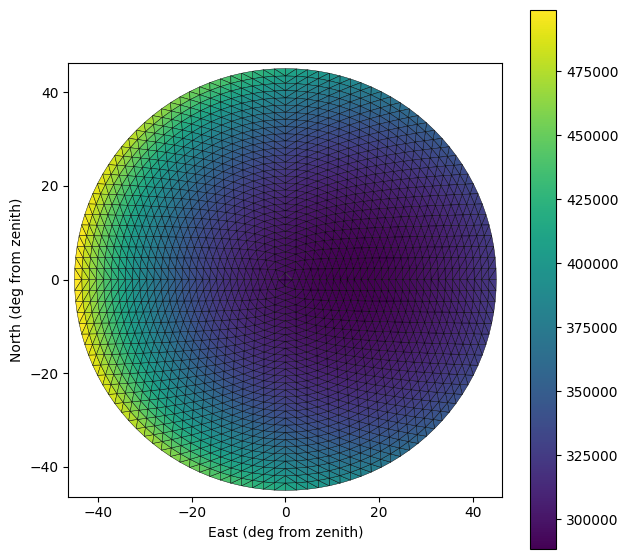

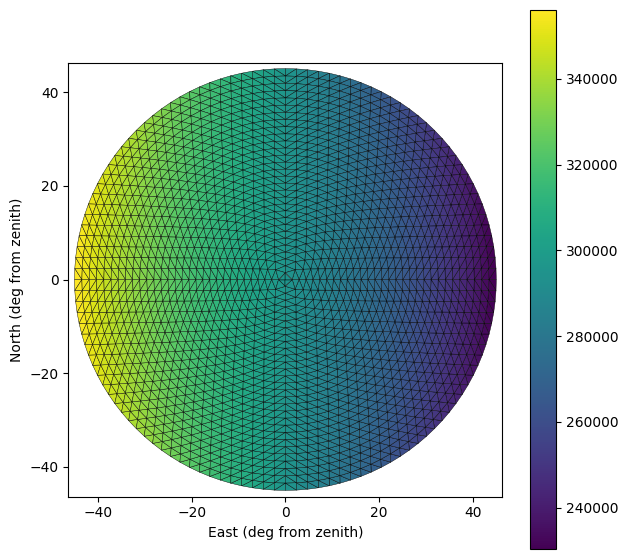

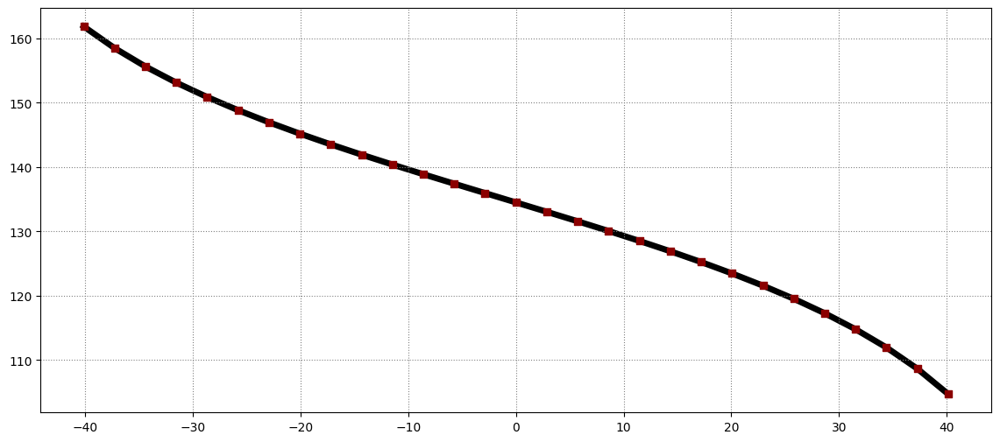

In [100]:
det.origin = [1500, 1500, -600]

density = 2200

regional_dip = 2.5
regional_strike = 90

model_fig4 = StratModel(nx=300, ny=300, dx=10)

model_fig4.add_basement(noise_scale=None, dip=regional_dip, strike=regional_strike)
model_fig4.deposit('h1', mean=200, noise_scale=None, rel_dip=-2.5, rel_strike=regional_strike)
#model_fig4.apply_fold(150, 3000, phase=0)

topo = Unconformity(dip=0, strike=90, z0=200)
model_fig4.apply_unconformity(topo)

model_top = model_fig4.horizons[model_fig4.order[-1]].max()

for lname in model_fig4.layer_order:
    #model_fig4.set_density(lname, mean=density, std=100)
    model_fig4.set_density(lname, mean=density, std=0)
    layer = model_fig4.layers[lname]

result = trace_rays_density(model_fig4, det.origin, det.central_dirs)
opacity = np.array([r.density_integral for r in result])
dstop = np.array([r.t_stop for r in result])

fig, ax = plot_layer_stack_slice(model_fig4, norm=plt.Normalize(vmin=1800,vmax=2450))[:2]
ax.scatter(det.origin[0], det.origin[2], marker='^', c='darkred')
for i, d in zip(det.central_dirs, dstop):
    ax.plot((det.origin[0], i[0]*d+det.origin[0]), (det.origin[2], i[2]*d+det.origin[2]),
            c='black', alpha=0.02)
ax.set_xlim((0, 3000))
ax.set_aspect('equal')

thickness_map = pov_correction(det.elevation_deg, opacity)/density

det.plot_sky(values=opacity)
det.plot_sky(values=pov_correction(det.elevation_deg, opacity))
# cmap = mpl.cm.get_cmap('terrain')
# colors = cmap(np.linspace(0, 0.8, 256))
# cmap = mpl.colors.LinearSegmentedColormap.from_list('trunc_cmap', colors)
# det.plot_sky(values=thickness_map, cmap=cmap)

axp = plot_polar_section(thickness_map, det.central_dirs, sample_res=29)[0]

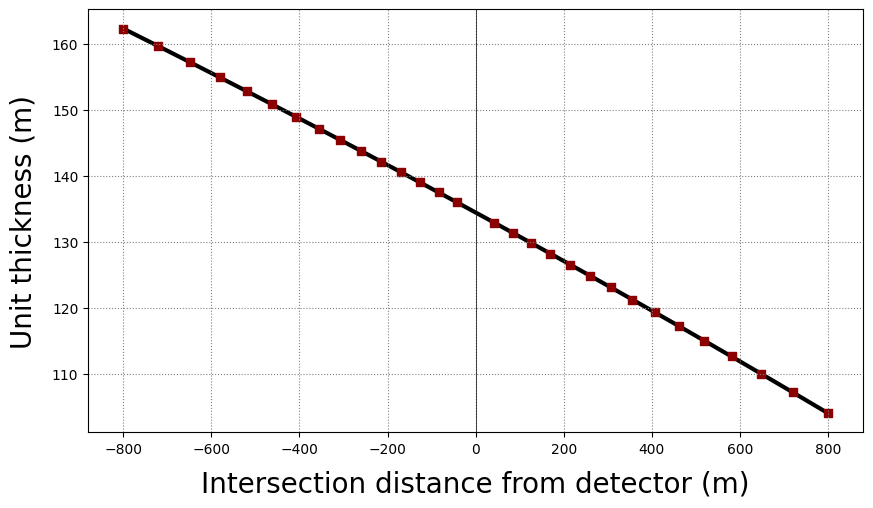

In [ ]:
horizontal_distance = np.array([
    r.t_stop * np.cos(np.radians(el)) if r.t_stop is not None else np.nan
    for r, el in zip(result, det.elevation_deg)
])
plot_data = thickness_map

target_az = 90
opposite_az = (target_az + 180) % 360
tol = 1

mask_pos = np.isclose(det.azimuth_deg, target_az, atol=tol)
mask_neg = np.isclose(det.azimuth_deg, opposite_az, atol=tol)

h_dist_signed = np.concatenate([-horizontal_distance[mask_neg], horizontal_distance[mask_pos]])
opacity_slice = np.concatenate([plot_data[mask_neg], plot_data[mask_pos]])

order = np.argsort(h_dist_signed)
h_dist_signed = h_dist_signed[order]
opacity_slice = opacity_slice[order]

plt.figure(figsize=(10,10))
plt.scatter(h_dist_signed, opacity_slice, marker='s', c='darkred', s=40, zorder=1)
plt.plot(h_dist_signed, opacity_slice, c='black', linewidth=3, zorder=0)
plt.axvline(0, color='k', lw=0.5)
plt.xlabel('Intersection distance from detector (m)', fontsize=20, labelpad=10)
plt.ylabel('Unit thickness (m)', fontsize=20, labelpad=10)
plt.grid(True, linestyle='dotted', color='0.5')
plt.gca().set_aspect(15)

Thickness at min x intersection: 161.85684148043532
Thickness at max x intersection: 104.71130117775138
Predicted thickness at min x: 104.71335653423357
Predicted thickness at max x: 161.854858612677


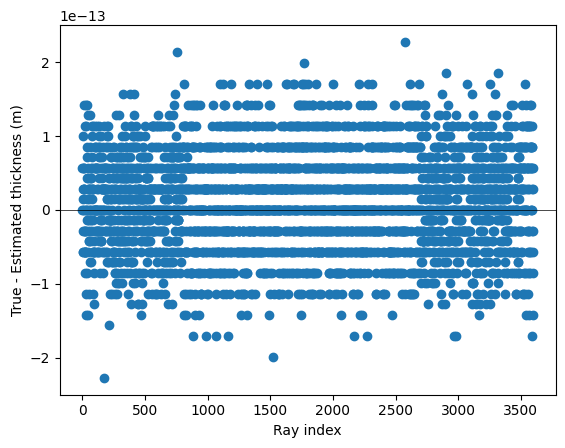

<Axes: xlabel='East (deg from zenith)', ylabel='North (deg from zenith)'>

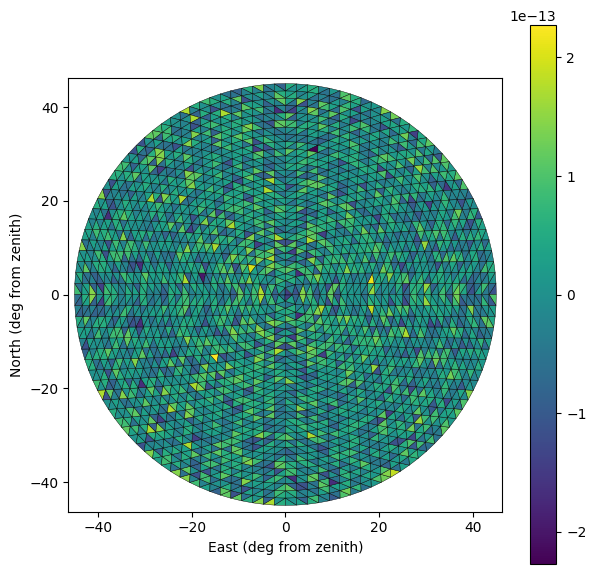

In [ ]:
#Testing estimated result againt actual model thicknesses
t_to_h1 = [
    next((c.point for c in r.crossings if c.horizon == 'basement'), None)
    for r in result]
t_to_h1 = np.vstack(t_to_h1)

print(
    f"Thickness at min x intersection: {layer_thickness_at(model_fig4, model.layer_order[0], x=t_to_h1[:,0].min(), y=1500)}"
)
print(
    f"Thickness at max x intersection: {layer_thickness_at(model_fig4, model.layer_order[0], x=t_to_h1[:,0].max(), y=1500)}"
)
line, thickness = get_polar_section(thickness_map, det.central_dirs, sample_res=29)
print(f"Predicted thickness at min x: {thickness.min()}")
print(f"Predicted thickness at max x: {thickness.max()}")

def true_thickness_per_ray(model, results, layer_name):
    out = np.full(len(results), np.nan)
    for i, r in enumerate(results):
        seg = next((s for s in r.segments if s.layer == layer_name), None)
        if seg is None:
            continue
        p = r.origin[0] + seg.t0 * r.direction[0], r.origin[1] + seg.t0 * r.direction[1]
        out[i] = layer_thickness_at(model, layer_name, p[0], p[1])
    return out

true_thickness = true_thickness_per_ray(model_fig4, result, model_fig4.layer_order[0])
diff = true_thickness - thickness_map


plt.figure()
plt.plot(diff, marker='o', ls='none')
plt.axhline(0, color='k', lw=0.5)
plt.xlabel('Ray index')
plt.ylabel('True - Estimated thickness (m)')
#plt.ylim((-1,1))
plt.show()

#norm=plt.Normalize(vmin=-1, vmax=1)
det.plot_sky(values=diff)

In [107]:
def make_circle(detector, model):
    # 2. Define the circle parameters
    center_x, center_y = detector.origin[:2]
    centre_z = model.horizons[model.order[-1]].max()
    radius = np.sin(45)* (centre_z - detector.origin[2])

    theta = np.linspace(0, 2 * np.pi, 100)

    x = center_x + radius * np.cos(theta)
    y = center_y + radius * np.sin(theta)
    z = np.full_like(theta, centre_z)

    return x,y,z

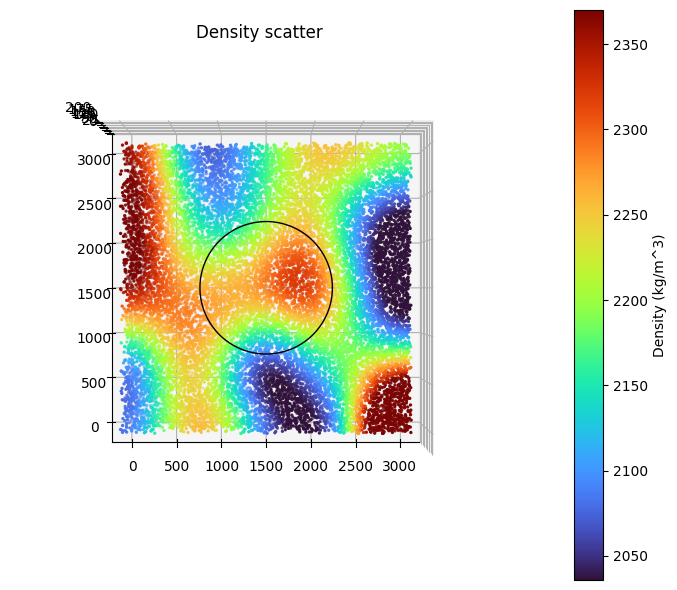

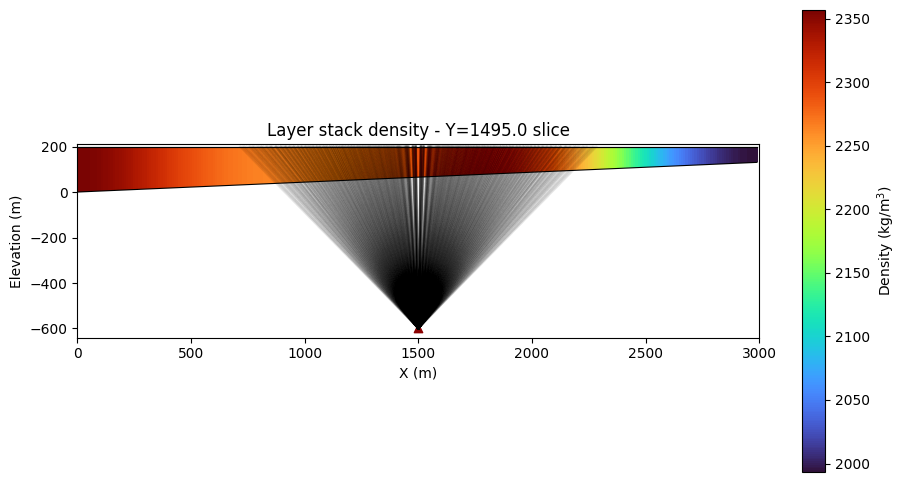

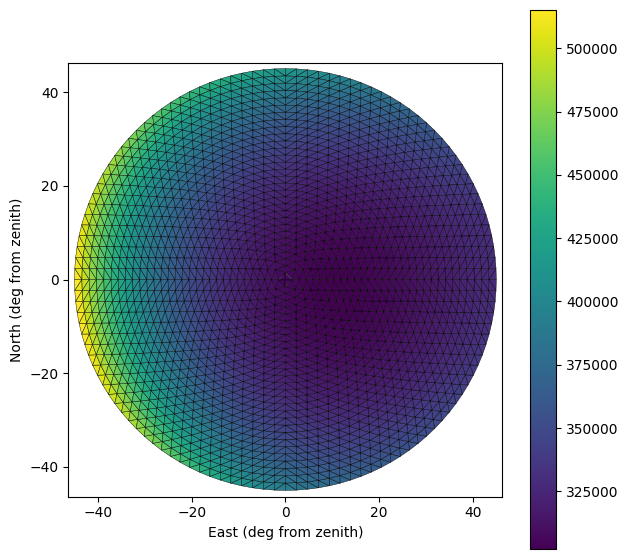

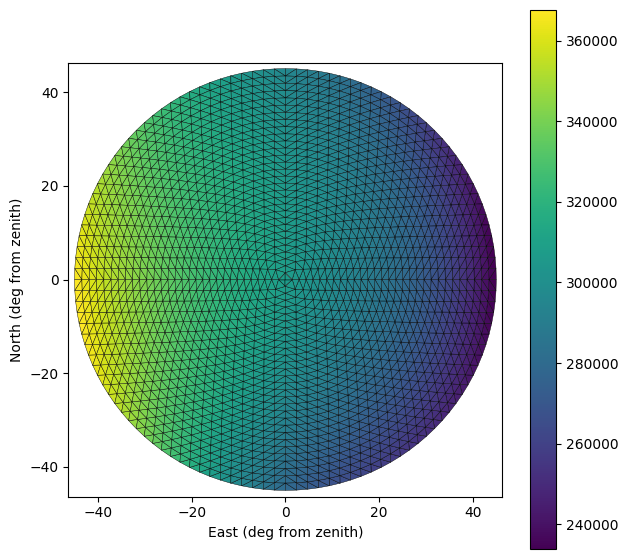

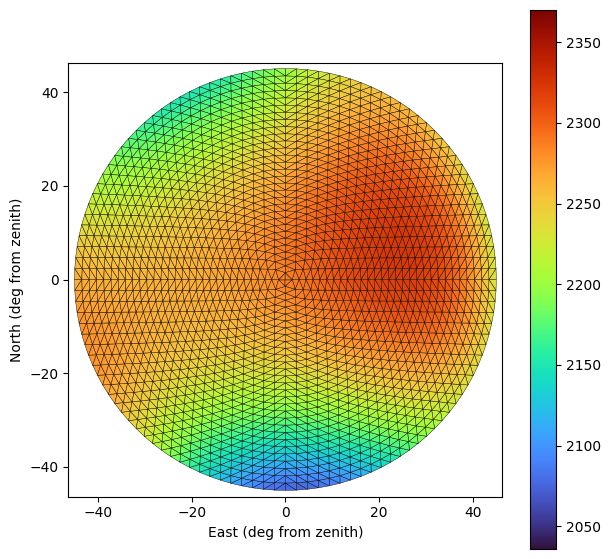

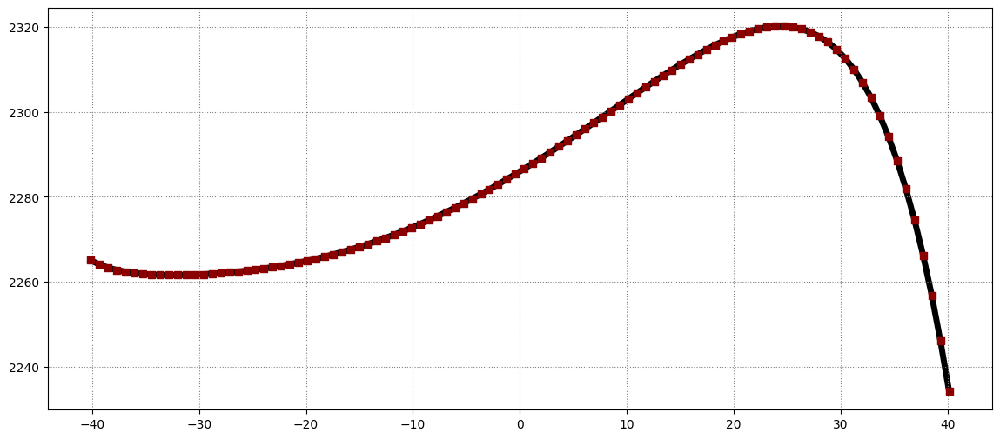

In [ ]:
for lname in model_fig4.layer_order:
    model_fig4.set_density(lname, mean=density, std=100, seed=6)
    #model_fig4.set_density(lname, mean=density, std=0)
    layer = model_fig4.layers[lname]

result = trace_rays_density(model_fig4, det.origin, det.central_dirs)
opacity = np.array([r.density_integral for r in result])
dstop = np.array([r.t_stop for r in result])

pov_map = pov_correction(det.elevation_deg, opacity)
density_map = pov_map / thickness_map

layer = model_fig4.layers['basement__h1']
pts = sample_density_points(
    model_fig4.X, model_fig4.Y,
    model_fig4.horizons[layer.base], model_fig4.horizons[layer.top],
    layer.density_model, n_points=20000, seed=1)

fig = plt.figure(figsize=(7, 6))
ax = fig.add_subplot(111, projection='3d')
ax.view_init(elev=90, azim=270)
norm = plt.Normalize(vmin=(density_map.min() - (density_map.min()*0.02)),
                     vmax=(density_map.max() + (density_map.max()*0.02)))
sc = ax.scatter(pts[:, 0], pts[:, 1], pts[:, 2], c=pts[:, 3], cmap='turbo', s=2, zorder=5, norm=norm)
circ_x, circ_y, circ_z = make_circle(det, model_fig4)
ax.plot3D(circ_x, circ_y, circ_z, color='black', linewidth='1', zorder=10)
plt.colorbar(sc, ax=ax, pad=0.1, label='Density (kg/m^3)')
ax.set_title(f'Density scatter')
plt.tight_layout(); plt.show()

fig, ax = plot_layer_stack_slice(model_fig4)[:2]
ax.scatter(det.origin[0], det.origin[2], marker='^', c='darkred')
for i, d in zip(det.central_dirs, dstop):
    ax.plot((det.origin[0], i[0]*d+det.origin[0]), (det.origin[2], i[2]*d+det.origin[2]),
            c='black', alpha=0.02)
ax.set_xlim((0, 3000))
ax.set_aspect('equal')

det.plot_sky(values=opacity)
det.data = pov_map
det.plot_sky(values=pov_map)
det.data = density_map
det.plot_sky(values=density_map, cmap='turbo', vmin=density_map.min() - density_map.min()*0.02, vmax=density_map.max() + (density_map.max()*0.02))

axp = plot_polar_section(density_map, det.central_dirs)[0]

<span style="font-size:30px; font-weight:bold;">Faulted stratigraphy</span>

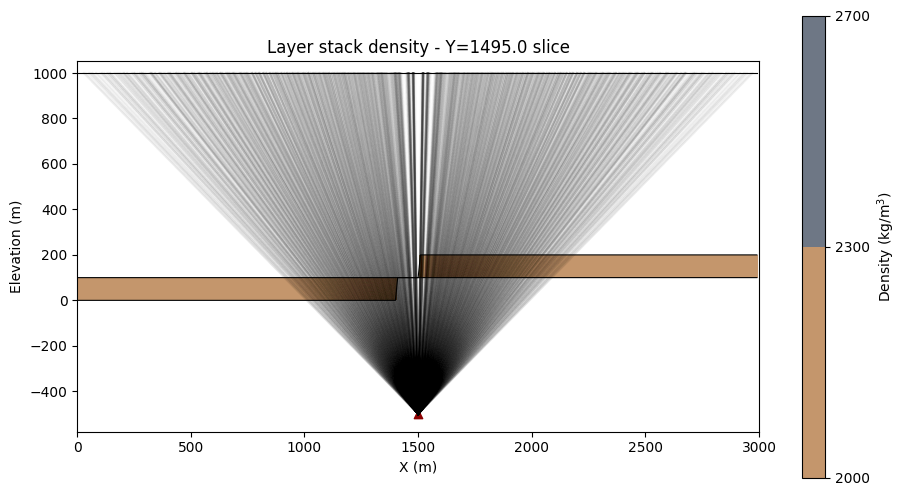

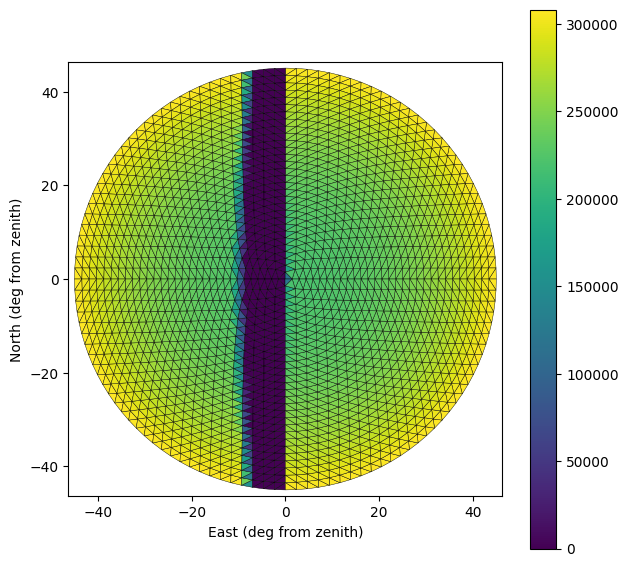

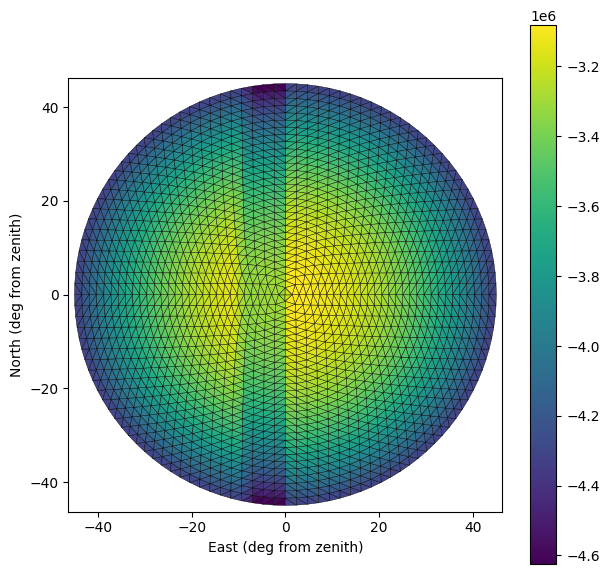

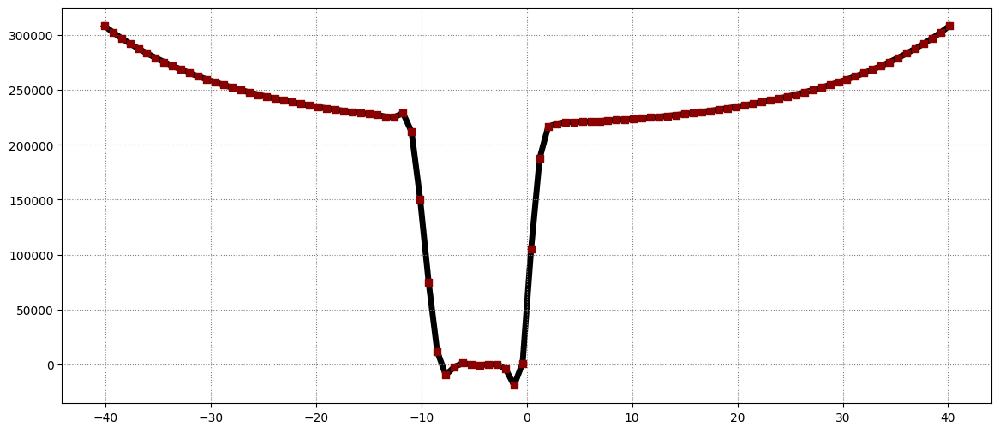

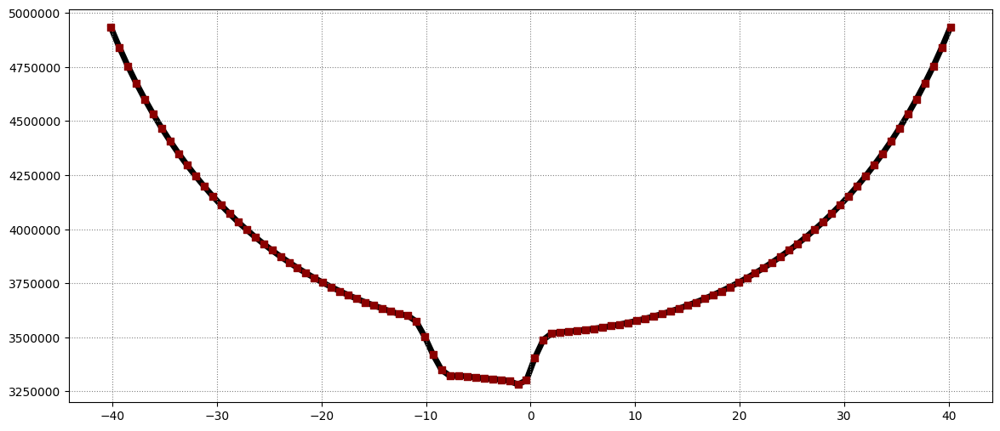

In [ ]:
#Not included in paper - stratigraphic modeller not yet equipped to handle layer truncation or duplication,
#and discretised form is too sensitive to aliasing from model cells
det.origin = [1500, 1500, -500]
densities = [2200, 2400]

regional_dip = 0
regional_strike = 90

model_fig6 = StratModel(nx=300, ny=300, dx=10)

model_fig6.add_basement(noise_scale=None, dip=regional_dip, strike=regional_strike)
model_fig6.deposit('h1', mean=100, noise_scale=None, rel_dip=0, rel_strike=regional_strike)


fault = Fault(45, regional_strike, -100, x0=1400)
model_fig6.apply_fault(fault)
#pinch_layer_at_fault(model_fig6, fault)
topo = Unconformity(dip=0, strike=90, z0=1000)
model_fig6.apply_unconformity(topo)

model_top = model_fig6.horizons[model_fig6.order[-1]].max()

ind=0
for lname in model_fig6.layer_order:
    if ind % 2 == 0:
        model_fig6.set_density(lname, mean=densities[0], std=0)
    else:
        model_fig6.set_density(lname, mean=densities[1], std=0)
    layer = model_fig6.layers[lname]
    ind += 1

result = trace_rays_density(model_fig6, det.origin, det.central_dirs)
opacity = np.array([r.density_integral for r in result])
dstop = np.array([r.t_stop for r in result])

boundaries = [2000, 2300,2700]   # kg/m^3 bin edges
colors     = ["#c4966c", "#6e7785"]  # one fewer color than boundaries
cmap = ListedColormap(colors)
norm = BoundaryNorm(boundaries, cmap.N)

fig, ax = plot_layer_stack_slice(model_fig6, cmap=cmap, norm=norm)[:2]
ax.scatter(det.origin[0], det.origin[2], marker='^', c='darkred')
for i, d in zip(det.central_dirs, dstop):
    ax.plot((det.origin[0], i[0]*d+det.origin[0]), (det.origin[2], i[2]*d+det.origin[2]),
            c='black', alpha=0.02)
ax.set_xlim((0, 3000))
ax.set_aspect('equal')

det.plot_sky(values=opacity)
det.plot_sky(values=opacity - (dstop*densities[0]))

axp = plot_polar_section(opacity, det.central_dirs)[0]
axp = plot_polar_section(opacity + (dstop*densities[0]), det.central_dirs)[0]

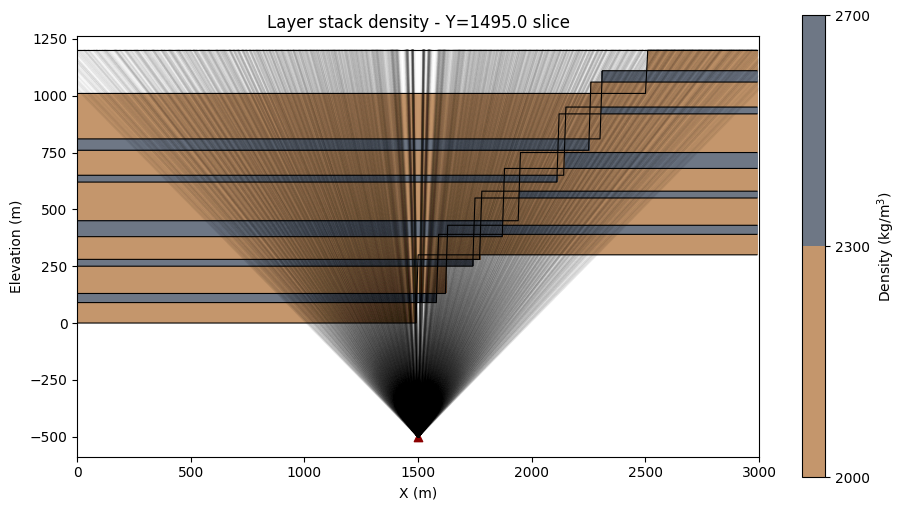

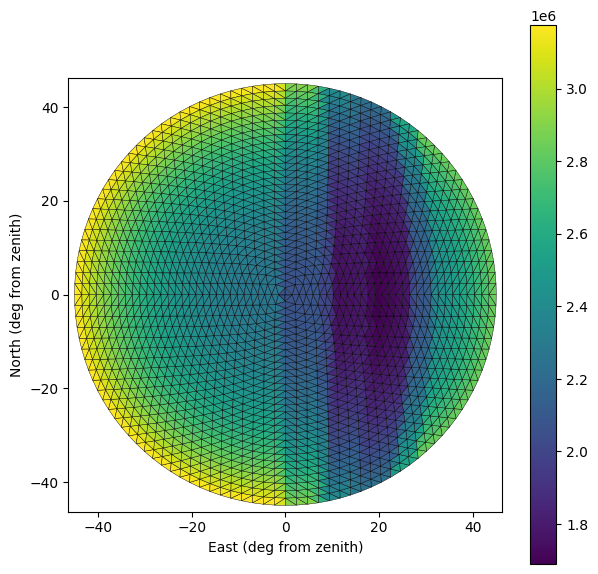

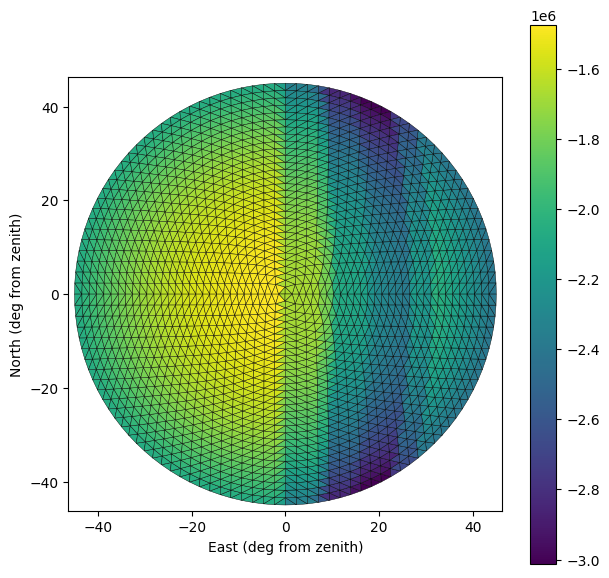

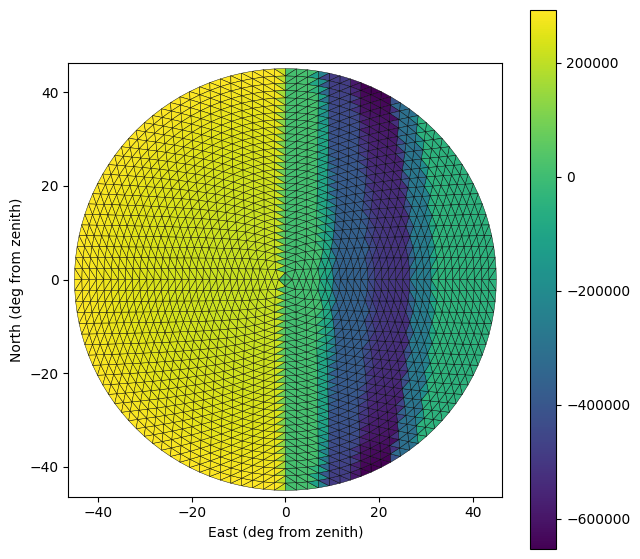

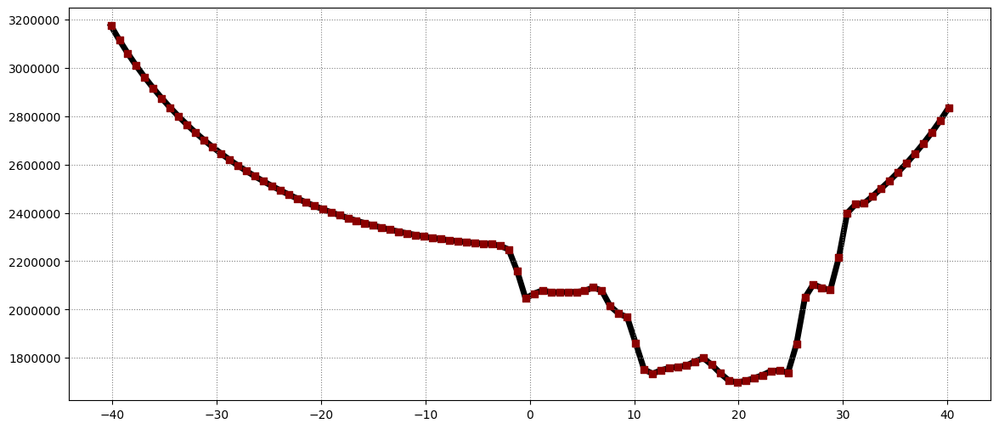

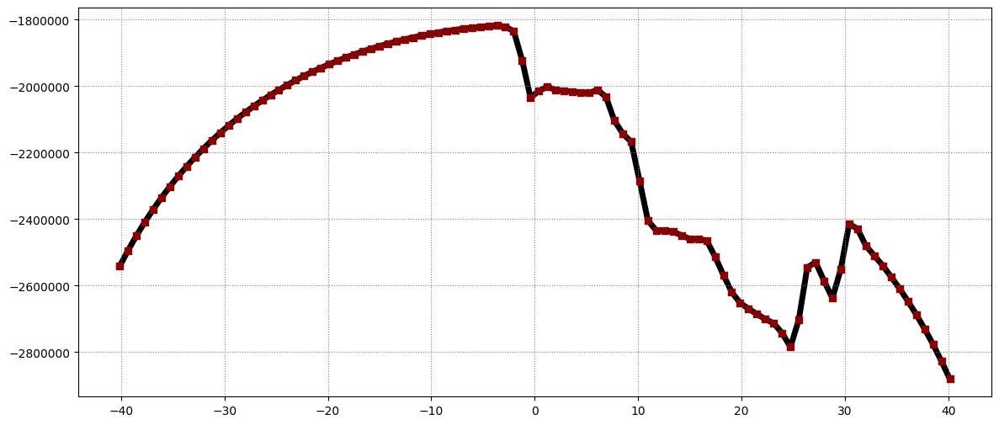

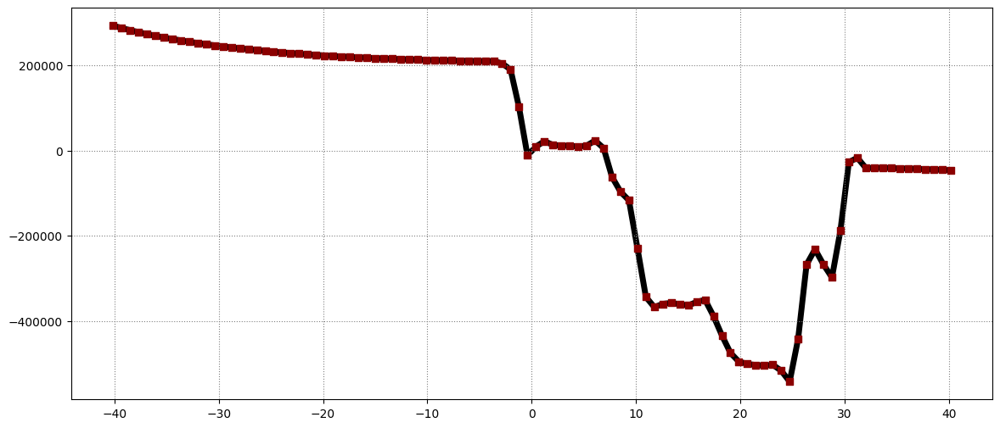

In [115]:
det.origin = [1500, 1500, -500]

densities = [2200, 2400]

regional_dip = 0
regional_strike = 90

model_fig6 = StratModel(nx=300, ny=300, dx=10)

model_fig6.add_basement(noise_scale=None, dip=regional_dip, strike=regional_strike)
model_fig6.deposit('h1', mean=90, noise_scale=None, rel_dip=0, rel_strike=regional_strike)
model_fig6.deposit('h2', mean=40, noise_scale=None, rel_dip=0, rel_strike=regional_strike)
model_fig6.deposit('h3', mean=120, noise_scale=None, rel_dip=0, rel_strike=regional_strike)
model_fig6.deposit('h4', mean=30, noise_scale=None, rel_dip=0, rel_strike=regional_strike)
model_fig6.deposit('h5', mean=100, noise_scale=None, rel_dip=0, rel_strike=regional_strike)
model_fig6.deposit('h6', mean=70, noise_scale=None, rel_dip=0, rel_strike=regional_strike)
model_fig6.deposit('h7', mean=170, noise_scale=None, rel_dip=0, rel_strike=regional_strike)
model_fig6.deposit('h8', mean=30, noise_scale=None, rel_dip=0, rel_strike=regional_strike)
model_fig6.deposit('h9', mean=110, noise_scale=None, rel_dip=0, rel_strike=regional_strike)
model_fig6.deposit('h10', mean=50, noise_scale=None, rel_dip=0, rel_strike=regional_strike)
model_fig6.deposit('h11', mean=200, noise_scale=None, rel_dip=0, rel_strike=regional_strike)

fault = Fault(dip=45, strike=regional_strike, throw=-300,
              x0=model_fig6.X.mean(), y0=model_fig6.Y.mean())
model_fig6.apply_fault(fault)
# for layer in model_fig6.layer_order:
#     pinch_layer_at_fault(model, layer, fault)
topo = Unconformity(dip=0, strike=90, z0=1200)
model_fig6.apply_unconformity(topo)

model_top = model_fig6.horizons[model_fig6.order[-1]].max()

ind=0
for lname in model_fig6.layer_order:
    if ind % 2 == 0:
        model_fig6.set_density(lname, mean=densities[0], std=0)
    else:
        model_fig6.set_density(lname, mean=densities[1], std=0)
    layer = model_fig6.layers[lname]
    ind += 1

result = trace_rays_density(model_fig6, det.origin, det.central_dirs)
opacity = np.array([r.density_integral for r in result])
dstop = np.array([r.t_stop for r in result])

boundaries = [2000, 2300,2700]   # kg/m^3 bin edges
colors     = ["#c4966c", "#6e7785"]  # one fewer color than boundaries
cmap = ListedColormap(colors)
norm = BoundaryNorm(boundaries, cmap.N)

fig, ax = plot_layer_stack_slice(model_fig6, cmap=cmap, norm=norm)[:2]
ax.scatter(det.origin[0], det.origin[2], marker='^', c='darkred')
for i, d in zip(det.central_dirs, dstop):
    ax.plot((det.origin[0], i[0]*d+det.origin[0]), (det.origin[2], i[2]*d+det.origin[2]),
            c='black', alpha=0.02)
ax.set_xlim((0, 3000))
ax.set_aspect('equal')

det.plot_sky(values=opacity)
det.plot_sky(values=opacity - (dstop*densities[0]))
det.plot_sky(values=opacity - (dstop*np.average(opacity/dstop)))

axp = plot_polar_section(opacity, det.central_dirs)[0]
axp = plot_polar_section(opacity - (dstop*densities[1]), det.central_dirs)[0]
axp = plot_polar_section(opacity - (dstop*np.average(opacity/dstop)), det.central_dirs)[0]

<span style="font-size:30px; font-weight:bold;">Folds</span>

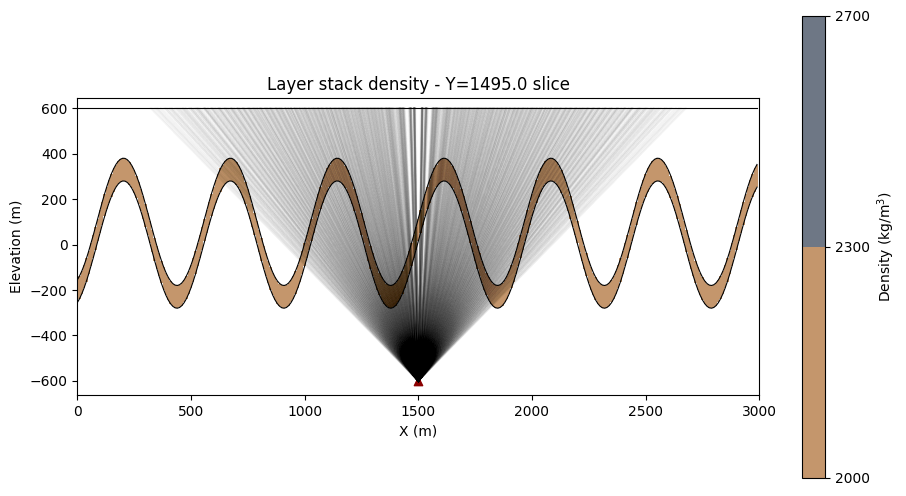

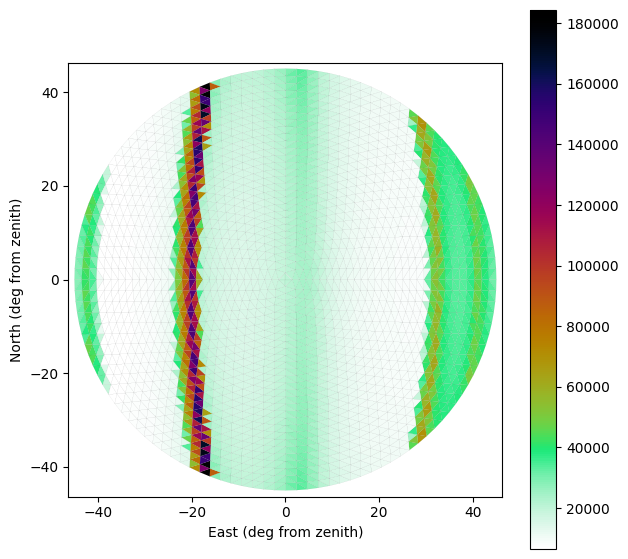

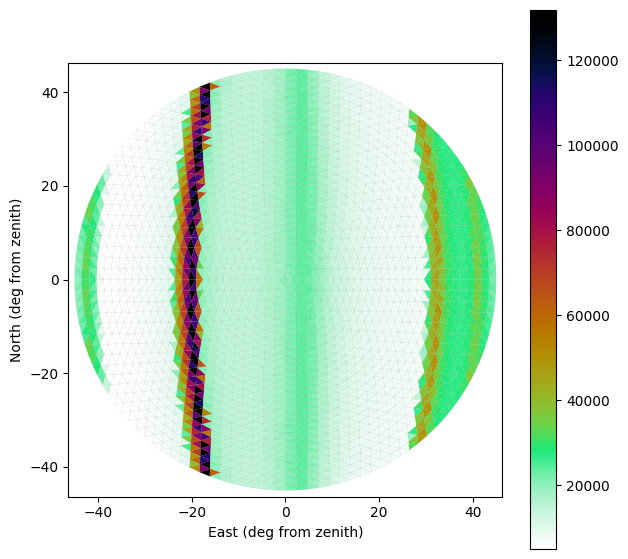

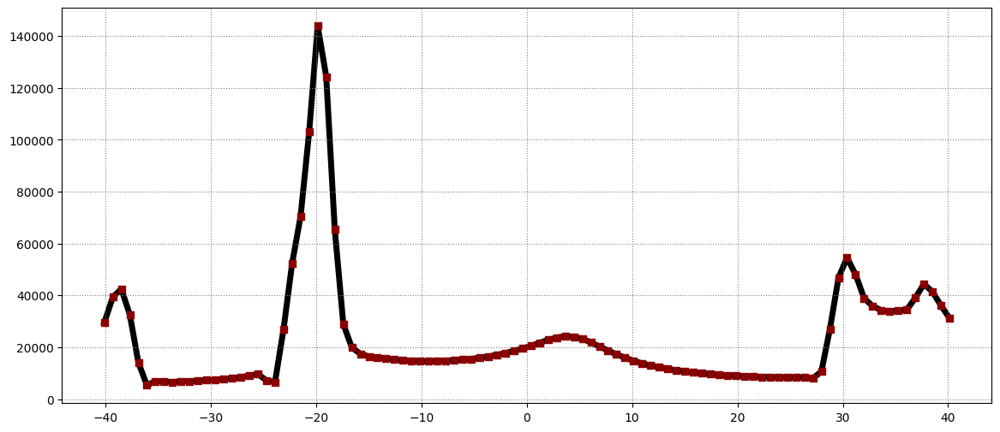

In [121]:
det.origin = [1500, 1500, -600]
densities = [200]

regional_dip = 0
regional_strike = 0

model_fig8 = StratModel(nx=300, ny=300, dx=10)

model_fig8.add_basement(noise_scale=None, dip=regional_dip, strike=regional_strike)
model_fig8.deposit('h1', mean=100, noise_scale=None, rel_dip=0, rel_strike=regional_strike)


model_fig8.apply_fold(280, 470, phase=-20)
topo = Unconformity(dip=0, strike=90, z0=600)
model_fig8.apply_unconformity(topo)

model_top = model_fig8.horizons[model_fig8.order[-1]].max()


model_fig8.set_density("basement__h1", mean=densities[0], std=0)

result = trace_rays_density(model_fig8, det.origin, det.central_dirs)
opacity = np.array([r.density_integral for r in result])
dstop = np.array([r.t_stop for r in result])

boundaries = [2000, 2300,2700]   # kg/m^3 bin edges
colors     = ["#c4966c", "#6e7785"]  # one fewer color than boundaries
cmap = ListedColormap(colors)
norm = BoundaryNorm(boundaries, cmap.N)

fig, ax = plot_layer_stack_slice(model_fig8, cmap=cmap, norm=norm)[:2]
ax.scatter(det.origin[0], det.origin[2], marker='^', c='darkred')
for i, d in zip(det.central_dirs, dstop):
    ax.plot((det.origin[0], i[0]*d+det.origin[0]), (det.origin[2], i[2]*d+det.origin[2]),
            c='black', alpha=0.01)
ax.set_xlim((0, 3000))
ax.set_aspect('equal')

det.plot_sky(values=opacity, cmap=cmr.chroma_r, linewidth=0.02)
det.plot_sky(values=pov_correction(det.elevation_deg, opacity), cmap=cmr.chroma_r, linewidth=0.02)

axp = plot_polar_section(opacity, det.central_dirs)[0]

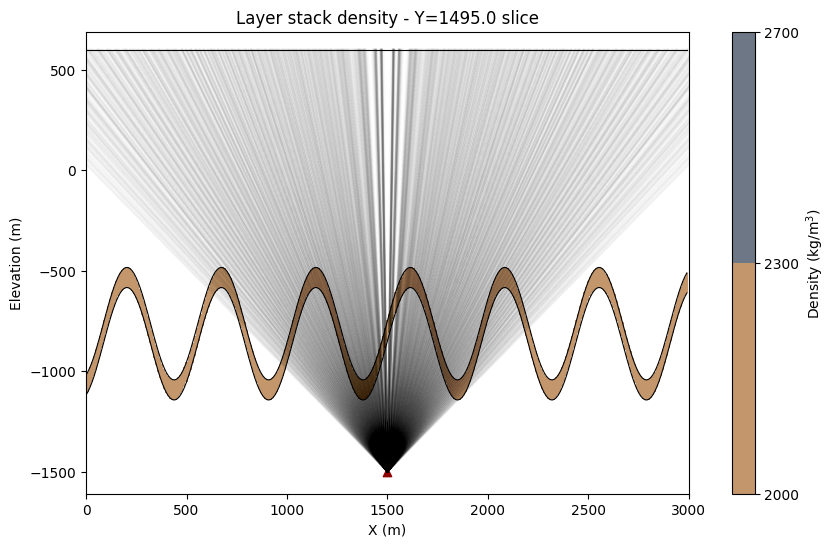

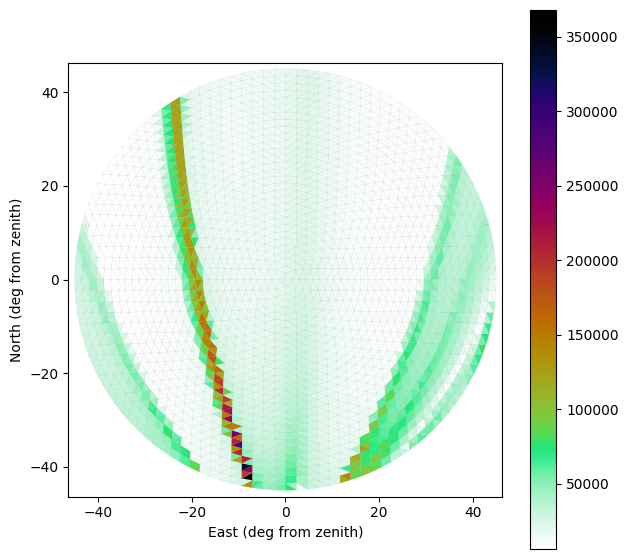

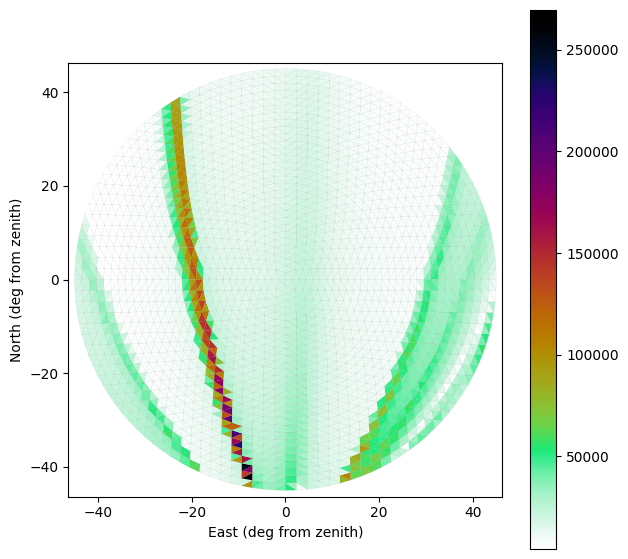

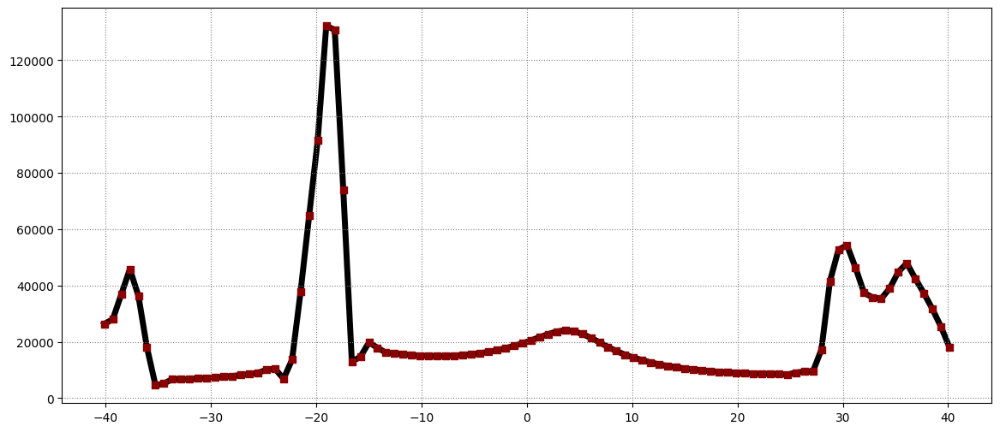

In [ ]:
# Same fold plunging 30deg
det.origin = [1500, 1500, -1500]
densities = [200]

regional_dip = 30
regional_strike = 0

model_fig8 = StratModel(nx=300, ny=300, dx=10)

model_fig8.add_basement(noise_scale=None, dip=regional_dip, strike=regional_strike)
model_fig8.deposit('h1', mean=100, noise_scale=None, rel_dip=0, rel_strike=regional_strike)


model_fig8.apply_fold(280, 470, phase=-20)
topo = Unconformity(dip=0, strike=90, z0=600)
model_fig8.apply_unconformity(topo)

model_top = model_fig8.horizons[model_fig8.order[-1]].max()


model_fig8.set_density("basement__h1", mean=densities[0], std=0)

result = trace_rays_density(model_fig8, det.origin, det.central_dirs)
opacity = np.array([r.density_integral for r in result])
dstop = np.array([r.t_stop for r in result])

boundaries = [2000, 2300,2700]   # kg/m^3 bin edges
colors     = ["#c4966c", "#6e7785"]  # one fewer color than boundaries
cmap = ListedColormap(colors)
norm = BoundaryNorm(boundaries, cmap.N)

fig, ax = plot_layer_stack_slice(model_fig8, cmap=cmap, norm=norm)[:2]
ax.scatter(det.origin[0], det.origin[2], marker='^', c='darkred')
for i, d in zip(det.central_dirs, dstop):
    ax.plot((det.origin[0], i[0]*d+det.origin[0]), (det.origin[2], i[2]*d+det.origin[2]),
            c='black', alpha=0.01)
ax.set_xlim((0, 3000))
ax.set_aspect('equal')

det.plot_sky(values=opacity, cmap=cmr.chroma_r, linewidth=0.02)
det.plot_sky(values=pov_correction(det.elevation_deg, opacity), cmap=cmr.chroma_r, linewidth=0.02)

axp = plot_polar_section(opacity, det.central_dirs)[0]

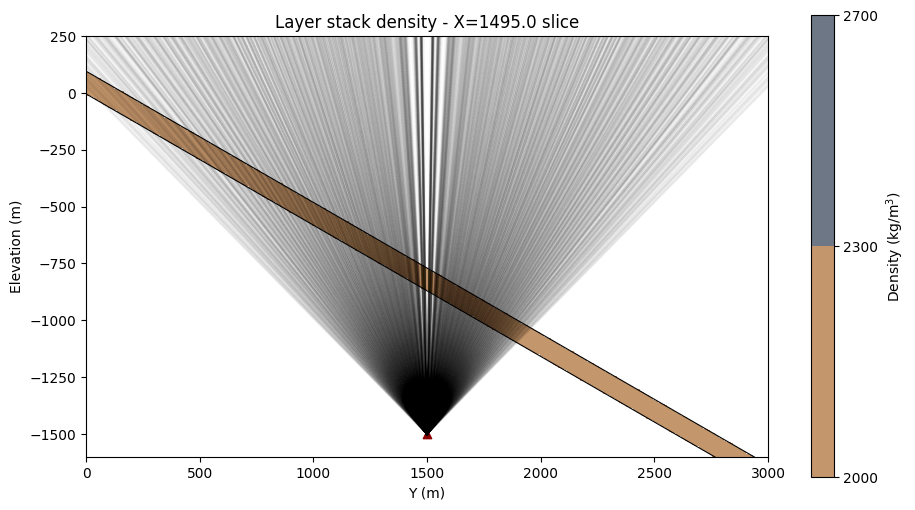

In [14]:
fig, ax = plot_layer_stack_slice(model_fig8, cmap=cmap, norm=norm, normal="X", equal_aspect=True)[:2]
ax.set_xlim(0, 3000)
ax.set_ylim(-1600, 250)
ax.scatter(det.origin[0], det.origin[2], marker='^', c='darkred')
for i, d in zip(det.central_dirs, dstop):
    ax.plot((det.origin[0], i[0]*d+det.origin[0]), (det.origin[2], i[2]*d+det.origin[2]),
            c='black', alpha=0.02)

In [136]:
def unit_vector_to_mplstereonet(n, rotate=180):
    n = np.asarray(n, dtype=float)
    n = n / np.linalg.norm(n, axis=-1, keepdims=True)

    angle = np.radians(rotate)

    x = n[..., 0] * np.cos(angle) - n[..., 1] * np.sin(angle)
    y = n[..., 0] * np.sin(angle) + n[..., 1] * np.cos(angle)
    z = n[..., 2]

    return mplstereonet.xyz2stereonet(x, y, z)

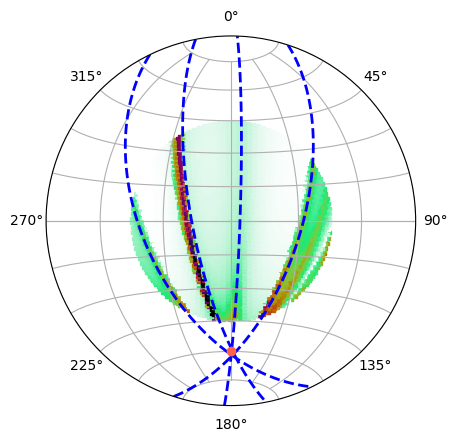

In [137]:
lon, lat = unit_vector_to_mplstereonet(det.central_dirs)
lon = np.arctan2(-np.sin(lon), -np.cos(lon))
lat = -lat

fig = plt.figure()
ax = fig.add_subplot(projection="stereonet")
ax.grid(True)
norm = plt.Normalize(vmin=opacity.min(), vmax=opacity.max()*0.5)
ax.scatter(lon, lat, c=opacity, s=5, marker='s', cmap=cmr.chroma_r, norm=norm)

ax.plane(154, 51, color='blue', linewidth=2, ls='--')
ax.plane(169, 73, color='blue', linewidth=2, ls='--')
ax.plane(2, 86, color='blue', linewidth=2, ls='--')
ax.plane(18, 59, color='blue', linewidth=2, ls='--')
ax.pole(270, 60, c='tomato')

In [138]:
def stereonet_cross_section(
    lon, lat, values,
    trend, plunge,
    n_samples=50,
    method="linear"
):
    # Convert plane orientation to Cartesian normal
    strike = trend % 360
    dip = plunge

    # Generate the great circle representing the plane
    section_lon, section_lat = mplstereonet.plane(
        strike, dip, segments=n_samples
    )

    # Interpolate scattered data along the plane
    points = np.column_stack((lon, lat))
    section_points = np.column_stack((section_lon, section_lat))

    section_values = griddata(
        points,
        values,
        section_points,
        method=method
    )

    # Angular distance along the section in stereonet coordinates
    x, y, z = mplstereonet.stereonet2xyz(
        section_lon, section_lat
    )

    xyz = np.column_stack((x, y, z))

    angular_steps = np.arccos(
        np.clip(np.sum(xyz[:-1] * xyz[1:], axis=1), -1, 1)
    )

    distance = np.concatenate((
        [0],
        np.cumsum(angular_steps)
    ))

    distance = np.degrees(distance)

    return distance, section_values, section_lon, section_lat

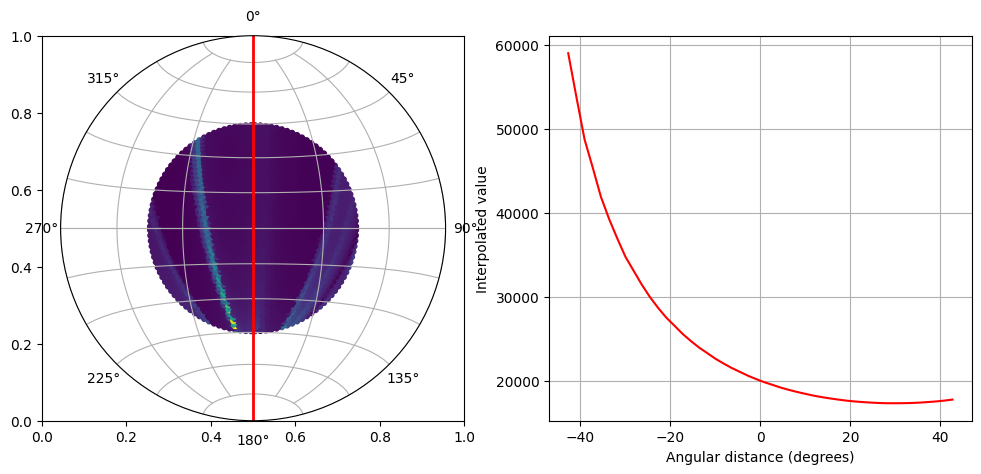

In [ ]:
distance, section, slon, slat = stereonet_cross_section(
    lon, lat, opacity,
    trend=0,
    plunge=90,
    n_samples=100
)
distance -= 90

fig, (ax1, ax2) = plt.subplots(
    1, 2, figsize=(12, 5)
)

# Stereonet
ax1 = fig.add_subplot(121, projection="stereonet")
ax1.grid(True)
ax1.scatter(lon, lat, c=opacity, s=12, cmap="viridis")
ax1.plot(slon, slat, 'r-', linewidth=2)

# Cross-section
ax2.plot(distance, section, 'r-')
ax2.set_xlabel("Angular distance (degrees)")
ax2.set_ylabel("Interpolated value")
ax2.grid(True)

plt.tight_layout()
plt.show()

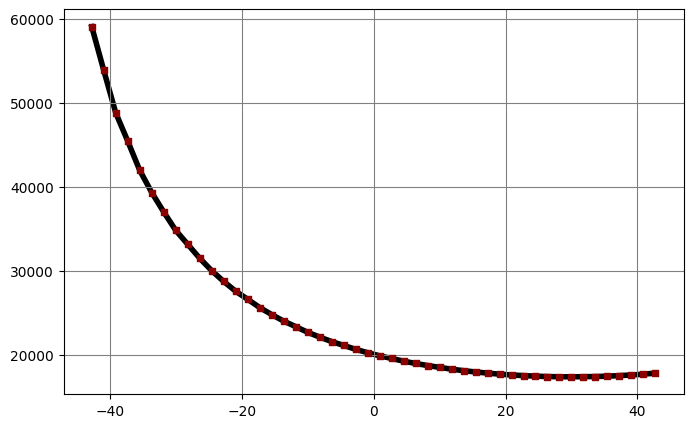

In [147]:
fig, ax = plt.subplots(figsize=(8,5))

ax.plot(distance, section, linewidth=4, c='black', zorder=0)
ax.scatter(distance, section, s=15, marker='s', c='darkred', zorder=1)
ax.ticklabel_format(style='plain', axis='y', useOffset=False)
ax.yaxis.set_major_formatter('{x:.0f}')


ax.grid(True, color='0.5')

ax.set_axisbelow(True)

<span style="font-size:30px; font-weight:bold;">TiltExplorer</span>

In [ ]:
from matplotlib.collections import PolyCollection
from matplotlib.patches import Circle

In [ ]:
class TiltExplorer:
    """Drag a dot on a polar opacity map to set the tilted axis used by `project_opacity`.

    det      : HealpixDetector (its `central_dirs` are the ray directions)
    opacity  : (det.n_cells,) opacity per cell, in kg/m^2
    offset_deg, toward_azimuth_deg : starting axis (0, 0 = vertical)
    max_offset_deg : furthest the dot can be dragged from the centre. Default: the edge of the
        plot_sky view. A larger value zooms the map out so the dot stays visible.
    scale  : 'fixed' - one colour range covering every axis the dot can take (magnitudes are
             comparable as you drag), or 'auto' - restretch to the current values each move.
             Press 'a' to toggle.
    unit   : opacities are shown divided by this (1e6 -> units of 10^6 kg/m^2)
    on_change : optional callback `f(tool)`, called after every update

    Read the result any time: tool.axis (unit vector), tool.offset_deg, tool.azimuth_deg,
    tool.projected (kg/m^2, one value per cell).
    """

    _COMPASS = ["N", "NNE", "NE", "ENE", "E", "ESE", "SE", "SSE",
                "S", "SSW", "SW", "WSW", "W", "WNW", "NW", "NNW"]

    def __init__(self, det, opacity, offset_deg=0.0, toward_azimuth_deg=0.0, max_offset_deg=None,
                 scale="fixed", cmap="magma", unit=1e6, label=r"Projected opacity (10$^6$ kg/m$^2$)",
                 on_change=None, figsize=(8.0, 6.6)):
        self.det = det
        self.opacity = np.asarray(opacity, dtype=float).ravel()
        if self.opacity.shape != (det.n_cells,):
            raise ValueError(f"opacity must have one value per detector cell ({det.n_cells}), "
                             f"got shape {self.opacity.shape}")
        if scale not in ("fixed", "auto"):
            raise ValueError("scale must be 'fixed' or 'auto'")
        self.dirs = np.asarray(det.central_dirs, dtype=float)
        self.unit, self.scale, self.on_change = float(unit), scale, on_change
        self._drag = False

        # how far the dot may go: by default the edge of the plot_sky view
        view_edge = 90.0 - det.elevation_deg.min() + det.resolution_deg
        self.max_offset = float(max_offset_deg) if max_offset_deg else float(view_edge)

        # one colour range that covers every axis the dot can take
        offs = np.linspace(0.0, self.max_offset, 12)
        azs = np.arange(0.0, 360.0, 15.0)
        allv = np.concatenate([project_opacity(self.opacity, self.dirs, tilted_axis(o, a))
                               for o in offs for a in azs]) / self.unit
        self.vmin, self.vmax = float(allv.min()), float(allv.max())

        # the map itself is plot_sky, so it looks exactly like the usual detector plot
        self.fig, self.ax = plt.subplots(figsize=figsize)
        start = project_opacity(self.opacity, self.dirs, tilted_axis(offset_deg, toward_azimuth_deg)) / self.unit
        det.plot_sky(values=start, ax=self.ax, cmap=cmap, label=label, vmin=self.vmin, vmax=self.vmax)
        self.pc = [c for c in self.ax.collections if isinstance(c, PolyCollection)][-1]

        lim = max(self.ax.get_xlim()[1], self.max_offset)
        self.ax.set_xlim(-lim, lim)
        self.ax.set_ylim(-lim, lim)
        for r in np.arange(10.0, lim + 1e-9, 10.0):                       # tilt-angle rings every 10 degrees
            self.ax.add_patch(Circle((0, 0), r, fill=False, ls=":", lw=0.8, ec="w", alpha=0.55, zorder=3))
        self.line_bg, = self.ax.plot([0, 0], [0, 0], color="w", lw=3.2, zorder=4)
        self.line, = self.ax.plot([0, 0], [0, 0], color="k", lw=1.2, ls="--", zorder=5)
        self.dot, = self.ax.plot([0], [0], "o", ms=13, mfc="cyan", mec="k", mew=1.5, zorder=6)
        self.text = self.ax.text(0.02, 0.98, "", transform=self.ax.transAxes, va="top", ha="left",
                                 color="w", fontsize=9, zorder=7,
                                 bbox=dict(boxstyle="round,pad=0.35", fc="k", ec="none", alpha=0.65))
        self.ax.set_title("Drag the dot to set the projection axis   (r: reset,  a: colour scale)")

        c = self.fig.canvas
        self._cids = [c.mpl_connect("button_press_event", self._on_press),
                      c.mpl_connect("motion_notify_event", self._on_motion),
                      c.mpl_connect("button_release_event", self._on_release),
                      c.mpl_connect("key_press_event", self._on_key)]
        self.set_axis(offset_deg, toward_azimuth_deg)

    # ---- state -----------------------------------------------------------------------------
    def set_axis(self, offset_deg, toward_azimuth_deg):
        """Move the axis (and the dot) programmatically; the plot updates."""
        self.offset_deg = float(np.clip(offset_deg, 0.0, self.max_offset))
        self.azimuth_deg = float(toward_azimuth_deg) % 360.0
        self.axis = tilted_axis(self.offset_deg, self.azimuth_deg)
        self.projected = project_opacity(self.opacity, self.dirs, self.axis)

        vals = self.projected / self.unit
        self.pc.set_array(vals)
        if self.scale == "auto":
            lo, hi = float(vals.min()), float(vals.max())
            self.pc.set_clim(lo, hi if hi > lo else lo + 1e-12)
        else:
            self.pc.set_clim(self.vmin, self.vmax)

        a = np.radians(self.azimuth_deg)
        x, y = self.offset_deg * np.sin(a), self.offset_deg * np.cos(a)    # same convention as plot_sky
        self.dot.set_data([x], [y])
        self.line.set_data([0, x], [0, y])
        self.line_bg.set_data([0, x], [0, y])
        where = "vertical" if self.offset_deg < 0.05 else (
            f"leaning {self.offset_deg:.1f}\N{DEGREE SIGN} towards {self.azimuth_deg:.0f}\N{DEGREE SIGN} "
            f"({self._COMPASS[int(((self.azimuth_deg + 11.25) % 360) // 22.5)]})")
        self.text.set_text(f"axis: {where}\nprojected: {vals.min():.3g} to {vals.max():.3g}")
        if self.on_change is not None:
            self.on_change(self)
        self.fig.canvas.draw_idle()

    # ---- mouse / keyboard ------------------------------------------------------------------
    def _toolbar_busy(self):
        tb = getattr(self.fig.canvas, "toolbar", None)
        return bool(tb is not None and getattr(tb, "mode", ""))             # pan / zoom tool active

    def _move(self, event):
        # convert the pointer to data coordinates ourselves so the dot keeps following even when the
        # pointer leaves the axes while dragging
        x, y = self.ax.transData.inverted().transform((event.x, event.y))
        self.set_axis(min(np.hypot(x, y), self.max_offset), np.degrees(np.arctan2(x, y)) % 360.0)

    def _on_press(self, event):
        if event.button != 1 or event.inaxes is not self.ax or self._toolbar_busy():
            return
        self._drag = True
        self._move(event)

    def _on_motion(self, event):
        if self._drag and event.x is not None:
            self._move(event)

    def _on_release(self, event):
        self._drag = False

    def _on_key(self, event):
        if event.key == "r":
            self.set_axis(0.0, 0.0)
        elif event.key == "a":
            self.scale = "auto" if self.scale == "fixed" else "fixed"
            self.set_axis(self.offset_deg, self.azimuth_deg)

    def disconnect(self):
        """Stop listening to the mouse and keyboard (the plot stays)."""
        for cid in self._cids:
            self.fig.canvas.mpl_disconnect(cid)

    def __repr__(self):
        return (f"TiltExplorer(offset={self.offset_deg:.1f} deg, azimuth={self.azimuth_deg:.0f} deg, "
                f"{self.det.n_cells} cells)")

In [ ]:
%matplotlib tk

In [ ]:
tool = TiltExplorer(det, opacity, cmap="jet")
plt.show()